# BurstGPT 원본 데이터 EDA

`docs/prd.md`에 합의된 8개 항목을 확인하는 실행 가능한 분석 노트북입니다.

- **범위:** 전체 파일은 구조·품질·구성만 확인하고, 시계열·대화 분석은 `Conversation log` 전체를 사용합니다.
- **예측 목표:** 매 1분 경계 `t`에서 `[t, t+600초)`에 도착할 요청의 누적 입력·최종 출력 토큰 두 값을 예측합니다. 10분 뒤 한 시점의 값이나 분별 10개 값이 아닙니다. 출력은 10분 이후에 완료될 수 있습니다.
- **보존:** 원본 CSV를 덮어쓰거나 요청을 임의로 삭제하지 않습니다. 중복·토큰 0·긴 응답은 먼저 표시하고 그대로 유지합니다.
- **시간:** Timestamp는 기준 첫날 자정 이후의 상대 초입니다. 실제 달력 날짜나 요일을 부여하지 않습니다. 상대 일은 `Timestamp // 86400`, 하루 중 시각은 `Timestamp % 86400`입니다.
- **출력량 두 종류:** 도착 기준 출력량은 해당 시점에 도착한 요청들의 **최종** 출력 합계이고, 완료 기준 출력량은 해당 시점에 **완료된** 응답들의 전체 출력 합계입니다. 둘 다 순간 생성률은 아닙니다.
- **재실행:** pandas, numpy, matplotlib, scipy, IPython이 있는 Python 커널에서 위에서부터 실행합니다. 프로젝트 루트나 `eda/`에서 실행할 수 있습니다.
- **저장:** `eda/results/tables/`에 집계 CSV, `figures/`에 PNG, `summary.json`·`summary.md`에 요약, `manifest.json`에 원본 해시와 실행 환경을 저장합니다. 대화 ID 원문은 결과 파일에 내보내지 않습니다.

In [1]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import gc, hashlib, json, platform, sys
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import display, Markdown

root_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
ROOT = next((p for p in root_candidates if (p / 'data/BurstGPT_3.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('프로젝트 루트 또는 eda/에서 실행하세요: data/BurstGPT_3.csv 필요')
RAW = ROOT / 'data/BurstGPT_3.csv'
OUT = ROOT / 'eda/results'
TABLES, FIGURES = OUT / 'tables', OUT / 'figures'
for path in [TABLES, FIGURES]:
    path.mkdir(parents=True, exist_ok=True)

FORECAST_MINUTES = 10
FORECAST_SECONDS = FORECAST_MINUTES * 60
FORECAST_STEP_SECONDS = 60
HISTORY_MINUTES = 60
assert isinstance(FORECAST_MINUTES, int) and FORECAST_MINUTES > 0

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110,
                     'font.family': 'DejaVu Sans', 'axes.spines.top': False,
                     'axes.spines.right': False})

def save_table(frame, name, show=True, rows=20):
    frame.to_csv(TABLES / f'{name}.csv', index=False)
    if show:
        display(frame.head(rows))
    return frame

def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f'{name}.png', dpi=140, bbox_inches='tight')
    display(fig)
    plt.close(fig)

def digest(path):
    h = hashlib.sha256()
    with path.open('rb') as source:
        for chunk in iter(lambda: source.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

started = datetime.now(ZoneInfo('Asia/Seoul')).isoformat()
source_hash = digest(RAW)
manifest = {
    'started_at_kst': started, 'source': str(RAW.relative_to(ROOT)),
    'source_sha256': source_hash, 'source_bytes': RAW.stat().st_size,
    'forecast': {
        'horizon_minutes': FORECAST_MINUTES, 'horizon_seconds': FORECAST_SECONDS,
        'step_seconds': FORECAST_STEP_SECONDS, 'history_minutes': HISTORY_MINUTES,
        'target_window': '[t, t + horizon_seconds)', 'grouped_by': 'request_arrival',
        'targets': ['input_tokens', 'final_output_tokens'],
        'comparison_horizons_minutes': [5, FORECAST_MINUTES],
    },
    'python': sys.version, 'platform': platform.platform(),
    'packages': {name: importlib.metadata.version(name) for name in
                 ['pandas', 'numpy', 'matplotlib', 'scipy', 'ipython', 'nbformat', 'nbclient']},
    'policies': {
        'primary_log_type': 'Conversation log', 'duplicates': 'retain',
        'zero_tokens': 'retain_and_flag', 'outliers': 'retain_and_report',
        'time': 'relative_seconds_no_calendar_date',
        'interior_empty_bins': 'zero_under_continuous_collection_assumption',
        'observed_range_exterior': 'do_not_extend',
        'partial_edge_bins': 'flag_and_exclude_from_rate_comparisons',
        'elapsed_zero': 'retain; zero does not establish failure or missingness',
    },
}
print('분석 대상:', RAW.relative_to(ROOT))
print('원본 SHA-256:', source_hash)
print('Python:', platform.python_version())

Matplotlib is building the font cache; this may take a moment.


분석 대상: data/BurstGPT_3.csv
원본 SHA-256: 2299986a07388aa303ec2c41d1131e756db650a39ed6ef9dfe7cc3d7f9a43b8f
Python: 3.13.5


## 1. 기본 구조·품질

자료형, 결측·비수치·무한대·음수, 완전 중복, 토큰 합계 정합성을 확인합니다.
`Session ID`는 문자열로 보존합니다. 빈 문자열과 공통 대체값은 따로 점검합니다.
완전 중복은 **모든 열이 같은 행의 추가 사본 수**이고, 같은 시각에 도착한 서로 다른 요청과 구분합니다.

In [2]:
EXPECTED = ['Timestamp', 'Session ID', 'Elapsed time', 'Model',
            'Request tokens', 'Response tokens', 'Total tokens', 'Log Type']
NUMERIC = ['Timestamp', 'Elapsed time', 'Request tokens', 'Response tokens', 'Total tokens']
df = pd.read_csv(RAW, dtype={'Session ID': 'string', 'Model': 'category', 'Log Type': 'category'},
                 keep_default_na=False, low_memory=False)
assert list(df.columns) == EXPECTED, f'스키마 변경 확인 필요: {df.columns.tolist()}'
total_rows = len(df)
original_dtypes = df.dtypes.astype(str)
quality_records = []
for col in EXPECTED:
    blank = df[col].isna() | df[col].astype('string').str.strip().eq('').fillna(False)
    record = {'column': col, 'original_dtype': original_dtypes[col],
              'missing_or_blank': int(blank.sum())}
    if col in NUMERIC:
        values = pd.to_numeric(df[col], errors='coerce')
        record.update(non_numeric=int((values.isna() & ~blank).sum()),
                      infinite=int((values.notna() & ~np.isfinite(values)).sum()),
                      negative=int(values.lt(0).sum()), zero=int(values.eq(0).sum()),
                      fractional=int((values.notna() & np.isfinite(values) & values.mod(1).ne(0)).sum()))
        df[col] = values
    quality_records.append(record)
quality = save_table(pd.DataFrame(quality_records), '01_column_quality')
duplicate_extra = df.duplicated(keep='first')
df['_duplicate_extra'] = duplicate_extra
df['_token_mismatch'] = (df['Request tokens'] + df['Response tokens']).ne(df['Total tokens'])
by_type_quality = df.groupby('Log Type', observed=True).agg(
    rows=('Timestamp', 'size'), duplicate_extra_rows=('_duplicate_extra', 'sum'),
    token_mismatch_rows=('_token_mismatch', 'sum'),
    min_timestamp=('Timestamp', 'min'), max_timestamp=('Timestamp', 'max')).reset_index()
save_table(by_type_quality, '01_quality_by_log_type')
print(f'전체 {total_rows:,}행 × {len(EXPECTED)}열 / 완전 중복 추가 사본 {int(duplicate_extra.sum()):,}행')

,column,original_dtype,missing_or_blank,non_numeric,infinite,negative,zero,fractional
0,Timestamp,float64,0,0.0000,0.0000,0.0000,0.0000,0.0000
1,Session ID,string,5110404,NaN,NaN,NaN,NaN,NaN
2,Elapsed time,int64,0,0.0000,0.0000,0.0000,"3,175,935.0000",0.0000
3,Model,category,0,NaN,NaN,NaN,NaN,NaN
4,Request tokens,int64,0,0.0000,0.0000,0.0000,"387,962.0000",0.0000
5,Response tokens,int64,0,0.0000,0.0000,0.0000,"387,963.0000",0.0000
6,Total tokens,int64,0,0.0000,0.0000,0.0000,"387,962.0000",0.0000
7,Log Type,category,0,NaN,NaN,NaN,NaN,NaN


,Log Type,rows,duplicate_extra_rows,token_mismatch_rows,min_timestamp,max_timestamp
0,API log,5110404,347285,0,"19,454,781.0000","28,943,983.0000"
1,Conversation log,233617,0,0,"19,440,110.0000","28,943,974.0000"


전체 5,344,021행 × 8열 / 완전 중복 추가 사본 347,285행


## 2. 요청 유형·모델 구성과 대화형 표본

API와 대화형을 구분합니다. 이후 분석에는 대화형 전체를 사용하고, 원본의 중복·0·극단값은 자동 삭제하지 않습니다.
계산에 필요한 필드가 유효하지 않은 경우에는 해당 계산만 제외하고 제외 수를 기록합니다.

,Log Type,Model,rows,input_tokens,output_tokens,share_all_rows_pct
0,API log,ChatGPT,4395665,1578283325,230527209,82.2539
1,API log,GPT-4,714739,754672009,121826676,13.3746
2,Conversation log,ChatGPT,158117,124070605,31309345,2.9588
3,Conversation log,GPT-4,75500,98481960,32230160,1.4128


,conversation_rows,invalid_time_rows,invalid_token_rows,invalid_elapsed_rows,excluded_from_token_timeseries,duplicate_extra_rows_retained,zero_token_rows_retained,token_mismatch_rows
0,233617,0,0,0,0,0,1856,0


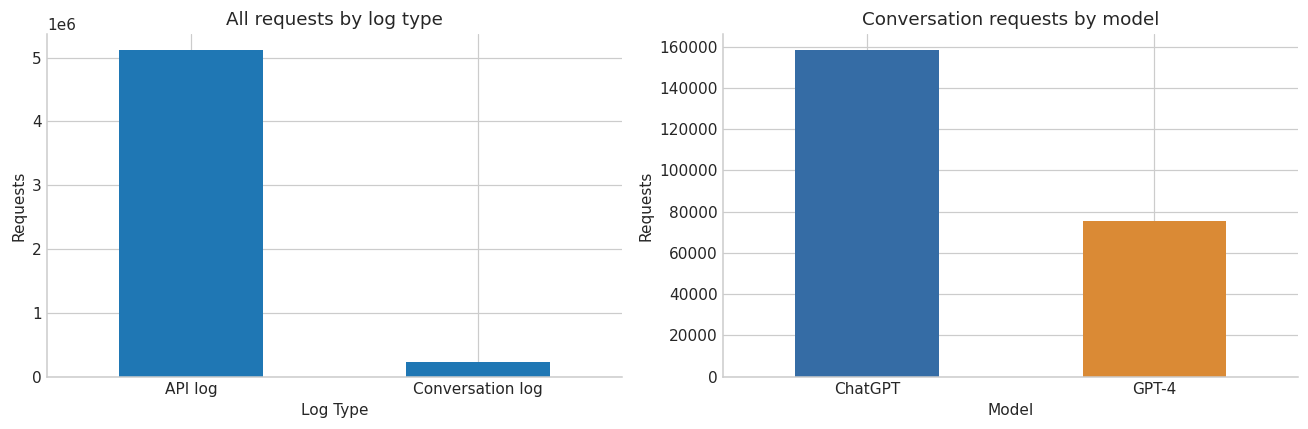

In [3]:
composition = df.groupby(['Log Type', 'Model'], observed=True).agg(
    rows=('Timestamp', 'size'), input_tokens=('Request tokens', 'sum'),
    output_tokens=('Response tokens', 'sum')).reset_index()
composition['share_all_rows_pct'] = composition['rows'] / total_rows * 100
save_table(composition, '02_log_model_composition')
all_min, all_max = float(df['Timestamp'].min()), float(df['Timestamp'].max())
conv = df.loc[df['Log Type'].eq('Conversation log'), EXPECTED].copy()
conv_duplicate_extra = int(by_type_quality.loc[by_type_quality['Log Type'].eq('Conversation log'), 'duplicate_extra_rows'].sum())
total_duplicates = int(duplicate_extra.sum())
total_token_mismatch = int(df['_token_mismatch'].sum())
del duplicate_extra, df
gc.collect()

finite = np.isfinite(conv[NUMERIC]).all(axis=1)
nonnegative = conv[NUMERIC].ge(0).all(axis=1)
time_ok = np.isfinite(conv['Timestamp']) & conv['Timestamp'].ge(0)
token_ok = np.isfinite(conv[['Request tokens', 'Response tokens', 'Total tokens']]).all(axis=1)
token_ok &= conv[['Request tokens', 'Response tokens', 'Total tokens']].ge(0).all(axis=1)
elapsed_ok = np.isfinite(conv['Elapsed time']) & conv['Elapsed time'].ge(0)
conv['_valid_time'] = time_ok
conv['_valid_tokens'] = token_ok
conv['_valid_elapsed'] = elapsed_ok
conv['_completion'] = (conv['Timestamp'] + conv['Elapsed time']).where(time_ok & elapsed_ok)
conv['_zero_token_record'] = conv[['Request tokens', 'Response tokens', 'Total tokens']].eq(0).all(axis=1)
conv['_elapsed_zero'] = conv['Elapsed time'].eq(0)
conv['_elapsed_ge_300'] = conv['Elapsed time'].ge(300)

ids = conv['Session ID'].str.strip()
placeholders = {'', 'nan', 'none', 'null', 'na', 'n/a', 'unknown', '0', '-', 'missing'}
conv['_valid_id'] = ids.notna() & ~ids.str.lower().isin(placeholders)
# 이번 파일에서 앞뒤 공백이 발견되면 자동 병합하지 않고 원본 ID를 유지합니다.
id_whitespace = int(conv['Session ID'].ne(ids).sum())
valid = conv.loc[time_ok & token_ok].sort_values('Timestamp', kind='stable').copy()
invalid_for_timeseries = int((~(time_ok & token_ok)).sum())
save_table(pd.DataFrame([{
    'conversation_rows': len(conv), 'invalid_time_rows': int((~time_ok).sum()),
    'invalid_token_rows': int((~token_ok).sum()), 'invalid_elapsed_rows': int((~elapsed_ok).sum()),
    'excluded_from_token_timeseries': invalid_for_timeseries,
    'duplicate_extra_rows_retained': conv_duplicate_extra,
    'zero_token_rows_retained': int(conv['_zero_token_record'].sum()),
    'token_mismatch_rows': int((conv['Request tokens'] + conv['Response tokens']).ne(conv['Total tokens']).sum()),
}]), '02_conversation_quality')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
composition.groupby('Log Type', observed=True)['rows'].sum().plot.bar(ax=axes[0], rot=0)
axes[0].set(title='All requests by log type', ylabel='Requests')
conv['Model'].value_counts().plot.bar(ax=axes[1], rot=0, color=['#356ca5', '#da8a35'])
axes[1].set(title='Conversation requests by model', ylabel='Requests')
save_fig(fig, '02_population_composition')

## 3. 관측 기간·연속성

실제 날짜 대신 관측 시작 이후 경과 일수와 상대 일을 사용합니다.
원본 60초 경계에 맞춰 관측 범위 **안쪽**의 빈 분만 0으로 채웁니다.
빈 구간은 실제 무요청인지 수집 누락인지 이 파일만으로 구분할 수 없습니다.
첫·마지막 분은 부분 관측일 수 있으므로 표시하고 비율·시간대 비교에서 제외합니다.

,relative_day,requests,input_tokens,arrival_final_output_tokens,full_observation
0,225,1635,1351550,393260,False
1,226,1353,1128458,346051,True
2,227,728,566935,202774,True
3,228,1010,896553,304040,True
4,229,1897,1727276,506879,True
5,230,1850,1513691,458643,True
6,231,1818,1600996,483133,True
7,232,1618,1375793,421563,True


,start_timestamp,end_timestamp_exclusive,empty_minutes,hours
0,20400420,20420820,340,5.6667
1,23941140,23961180,334,5.5667
2,22733520,22753260,329,5.4833
3,21955140,21972600,291,4.8500
4,25757340,25773120,263,4.3833
5,22045860,22061100,254,4.2333
6,26278380,26292780,240,4.0000
7,22390800,22405140,239,3.9833
8,20924400,20938320,232,3.8667
9,26537520,26550420,215,3.5833


,conversation_min_timestamp,conversation_max_timestamp,conversation_span_days,minute_bins,fully_observed_minute_bins,partial_edge_minute_bins,empty_full_minutes,empty_full_minutes_pct,longest_empty_minutes,longest_interarrival_seconds,full_relative_days,empty_full_relative_days,completion_after_last_arrival_rows,completion_outside_minute_grid_rows
0,"19,440,110.0000","28,943,974.0000",109.9984,158399,158397,2,72943,46.0507,340,"20,513.0000",108,0,1,0


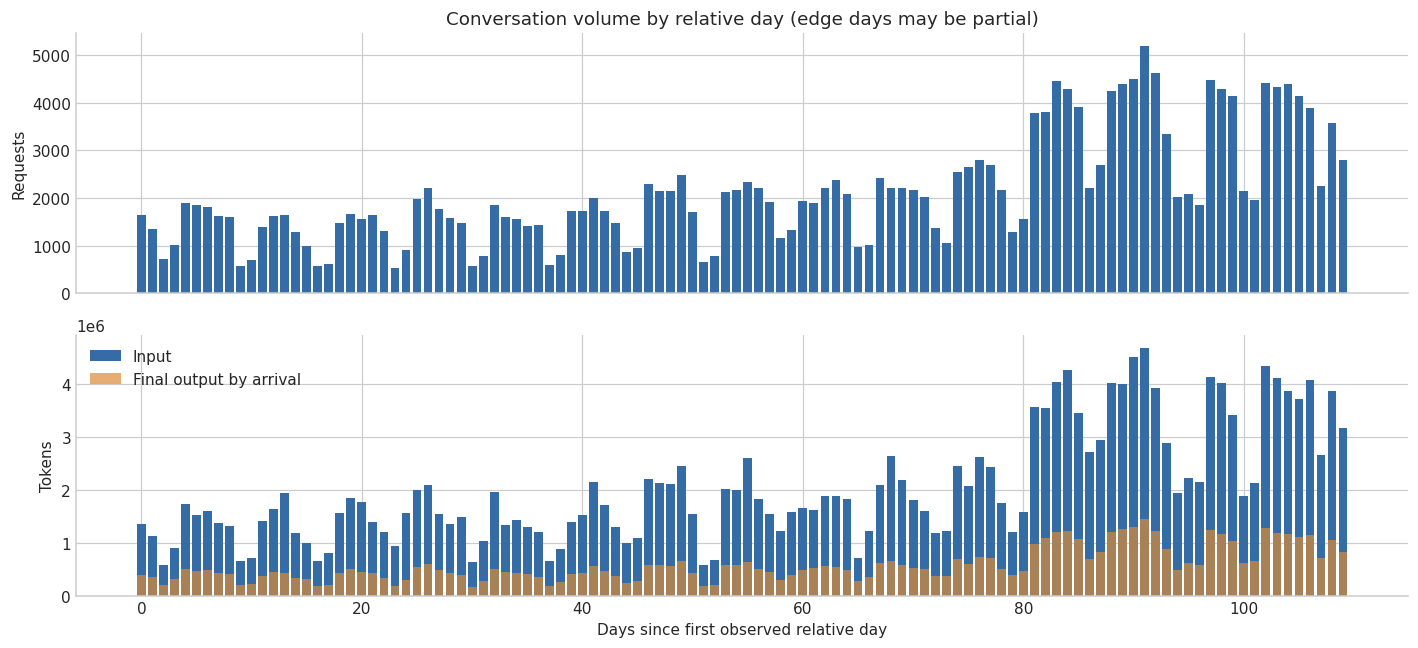

In [4]:
amin, amax = float(valid['Timestamp'].min()), float(valid['Timestamp'].max())
minute_first, minute_last = int(np.floor(amin / 60)), int(np.floor(amax / 60))
minute_ids = np.arange(minute_first, minute_last + 1, dtype=np.int64)
valid['_minute'] = np.floor(valid['Timestamp'] / 60).astype('int64')
valid['_relative_day'] = np.floor(valid['Timestamp'] / 86400).astype('int64')
arrival = valid.groupby('_minute').agg(
    requests=('Timestamp', 'size'), input_tokens=('Request tokens', 'sum'),
    arrival_final_output_tokens=('Response tokens', 'sum'),
    zero_token_requests=('_zero_token_record', 'sum'))
minute = arrival.reindex(minute_ids, fill_value=0).rename_axis('minute_id').reset_index()
minute['timestamp'] = minute['minute_id'] * 60
minute['elapsed_days'] = (minute['timestamp'] - amin) / 86400
minute['full_observation'] = minute['timestamp'].ge(amin) & (minute['timestamp'] + 60).le(amax)
minute['hour_of_day'] = (minute['timestamp'] % 86400 // 3600).astype(int)
minute['relative_day'] = (minute['timestamp'] // 86400).astype(int)

completion_requests = conv.loc[conv['_valid_time'] & conv['_valid_elapsed'] & conv['_valid_tokens']].copy()
completion_requests['_completion_minute'] = np.floor(completion_requests['_completion'] / 60).astype('int64')
completion_group = completion_requests.groupby('_completion_minute').agg(
    completed_requests=('Timestamp', 'size'), completed_output_tokens=('Response tokens', 'sum'))
minute = minute.merge(completion_group, left_on='minute_id', right_index=True, how='left')
minute[['completed_requests', 'completed_output_tokens']] = minute[['completed_requests', 'completed_output_tokens']].fillna(0)
full_minute = minute.loc[minute['full_observation']].copy()
assert minute['requests'].sum() == len(valid)
assert minute['input_tokens'].sum() == valid['Request tokens'].sum()
assert minute['arrival_final_output_tokens'].sum() == valid['Response tokens'].sum()
save_table(minute, '03_minute_timeseries', show=False)

daily = valid.groupby('_relative_day').agg(
    requests=('Timestamp', 'size'), input_tokens=('Request tokens', 'sum'),
    arrival_final_output_tokens=('Response tokens', 'sum')).reindex(
        np.arange(int(amin // 86400), int(amax // 86400) + 1), fill_value=0).rename_axis('relative_day').reset_index()
daily['full_observation'] = (daily['relative_day'] * 86400).ge(amin) & ((daily['relative_day'] + 1) * 86400).le(amax)
save_table(daily, '03_daily_volume', rows=8)

empty = full_minute['requests'].eq(0).to_numpy()
edges = np.diff(np.r_[False, empty, False].astype(int))
starts, stops = np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)
empty_runs = pd.DataFrame({
    'start_timestamp': full_minute['timestamp'].to_numpy()[starts],
    'end_timestamp_exclusive': full_minute['timestamp'].to_numpy()[stops - 1] + 60,
    'empty_minutes': stops - starts,
})
empty_runs['hours'] = empty_runs['empty_minutes'] / 60
empty_runs = empty_runs.sort_values('empty_minutes', ascending=False).reset_index(drop=True)
save_table(empty_runs, '03_empty_runs', rows=10)
request_gaps = valid['Timestamp'].diff().dropna()
coverage = {
    'conversation_min_timestamp': amin, 'conversation_max_timestamp': amax,
    'conversation_span_days': (amax - amin) / 86400,
    'minute_bins': len(minute), 'fully_observed_minute_bins': len(full_minute),
    'partial_edge_minute_bins': int((~minute['full_observation']).sum()),
    'empty_full_minutes': int(empty.sum()), 'empty_full_minutes_pct': float(empty.mean() * 100),
    'longest_empty_minutes': int(empty_runs['empty_minutes'].max()) if len(empty_runs) else 0,
    'longest_interarrival_seconds': float(request_gaps.max()),
    'full_relative_days': int(daily['full_observation'].sum()),
    'empty_full_relative_days': int((daily['full_observation'] & daily['requests'].eq(0)).sum()),
    'completion_after_last_arrival_rows': int(completion_requests['_completion'].gt(amax).sum()),
    'completion_outside_minute_grid_rows': int((~completion_requests['_completion_minute'].between(minute_first, minute_last)).sum()),
}
save_table(pd.DataFrame([coverage]), '03_coverage')
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
axes[0].bar(daily['relative_day'] - amin // 86400, daily['requests'], color='#356ca5')
axes[0].set(ylabel='Requests', title='Conversation volume by relative day (edge days may be partial)')
axes[1].bar(daily['relative_day'] - amin // 86400, daily['input_tokens'], label='Input', color='#356ca5')
axes[1].bar(daily['relative_day'] - amin // 86400, daily['arrival_final_output_tokens'], alpha=.7, label='Final output by arrival', color='#da8a35')
axes[1].set(xlabel='Days since first observed relative day', ylabel='Tokens'); axes[1].legend()
save_fig(fig, '03_daily_coverage')

## 4. 요청량·토큰량 시계열과 피크

1분·5분·10분·1시간의 **겹치지 않는 구간**으로 비교합니다. 집계 구간의 양 끝이 관측 범위에 들어오는 경우만 전체 관측 구간으로 표시합니다.
이 집계는 해상도 비교용이며, 매 1분 갱신하는 겹치는 10분 예측 목표는 §8에서 별도로 계산합니다.
출력은 도착 기준 최종 출력과 완료 기준 출력 이력을 각각 보존합니다.
그래프의 확대 구간은 관측 범위 안에서 입력 토큰량이 가장 큰 완전한 1시간 주변으로 선택합니다.

,resolution,measure,full_bins,zero_pct,mean,median,p95,p99,max
0,1min,requests,158397,46.0507,1.4749,1.0000,6.0000,9.0000,27.0000
1,1min,input_tokens,158397,46.2553,"1,405.0135",77.0000,"6,344.0000","11,382.1200","151,395.0000"
2,1min,arrival_final_output_tokens,158397,46.2553,401.1365,40.0000,"1,739.0000","2,805.0400","9,059.0000"
3,1min,completed_output_tokens,158397,46.3311,401.1393,40.0000,"1,738.0000","2,811.0000","9,627.0000"
4,5min,requests,31678,22.1921,7.3743,4.0000,26.0000,38.0000,82.0000
5,5min,input_tokens,31678,22.3089,"7,024.9391","3,533.0000","25,981.6500","41,382.0400","165,015.0000"
6,5min,arrival_final_output_tokens,31678,22.3089,"2,005.6771","1,146.0000","7,062.0500","10,819.1400","25,707.0000"
7,5min,completed_output_tokens,31678,22.3657,"2,005.6771","1,140.0000","7,087.4500","10,784.3800","24,262.0000"
8,10min,requests,15838,15.6901,14.7490,9.0000,50.0000,75.0000,137.0000
9,10min,input_tokens,15838,15.7911,"14,049.9103","7,934.0000","49,628.3000","76,336.2100","184,660.0000"


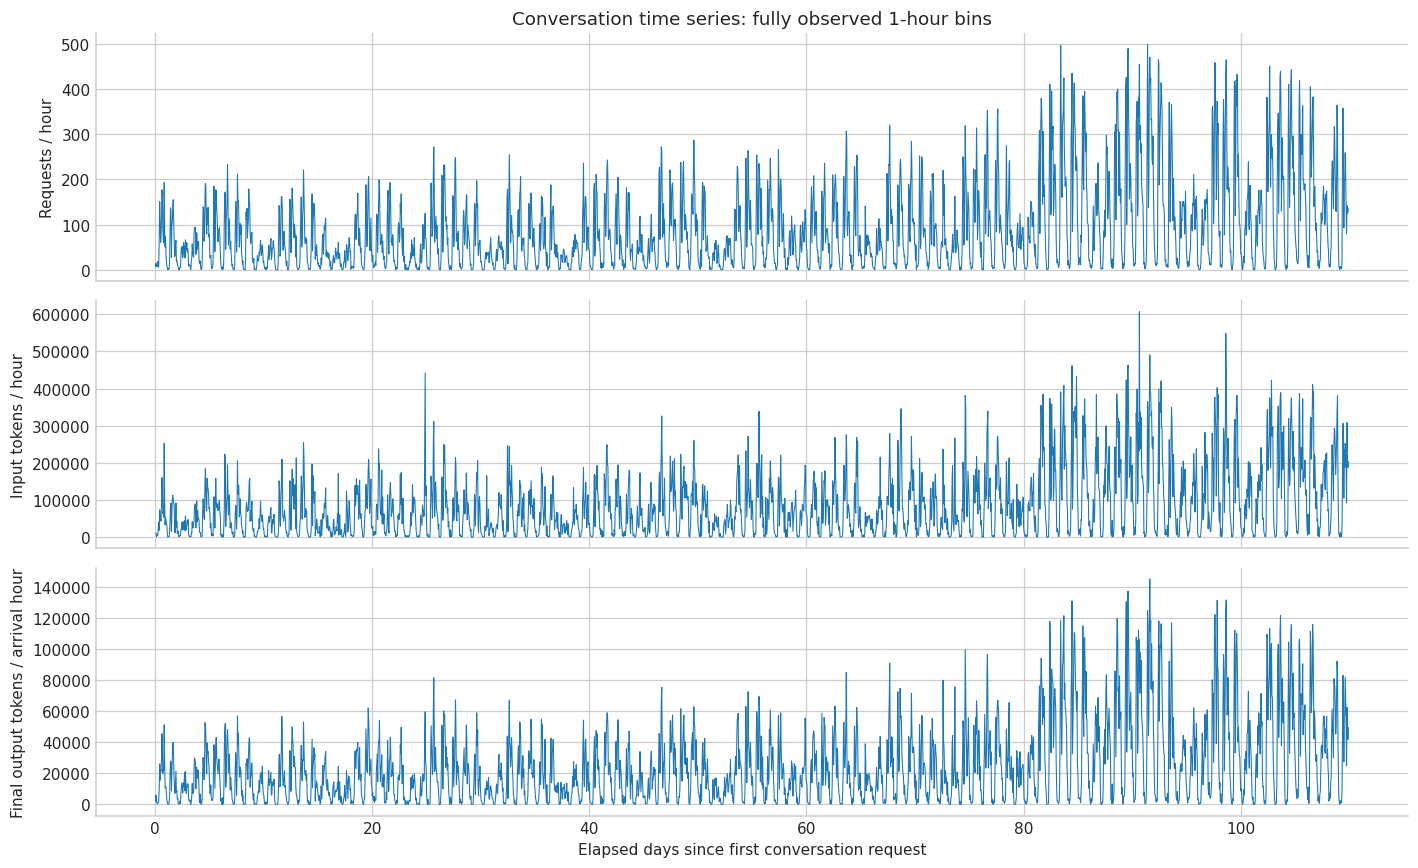

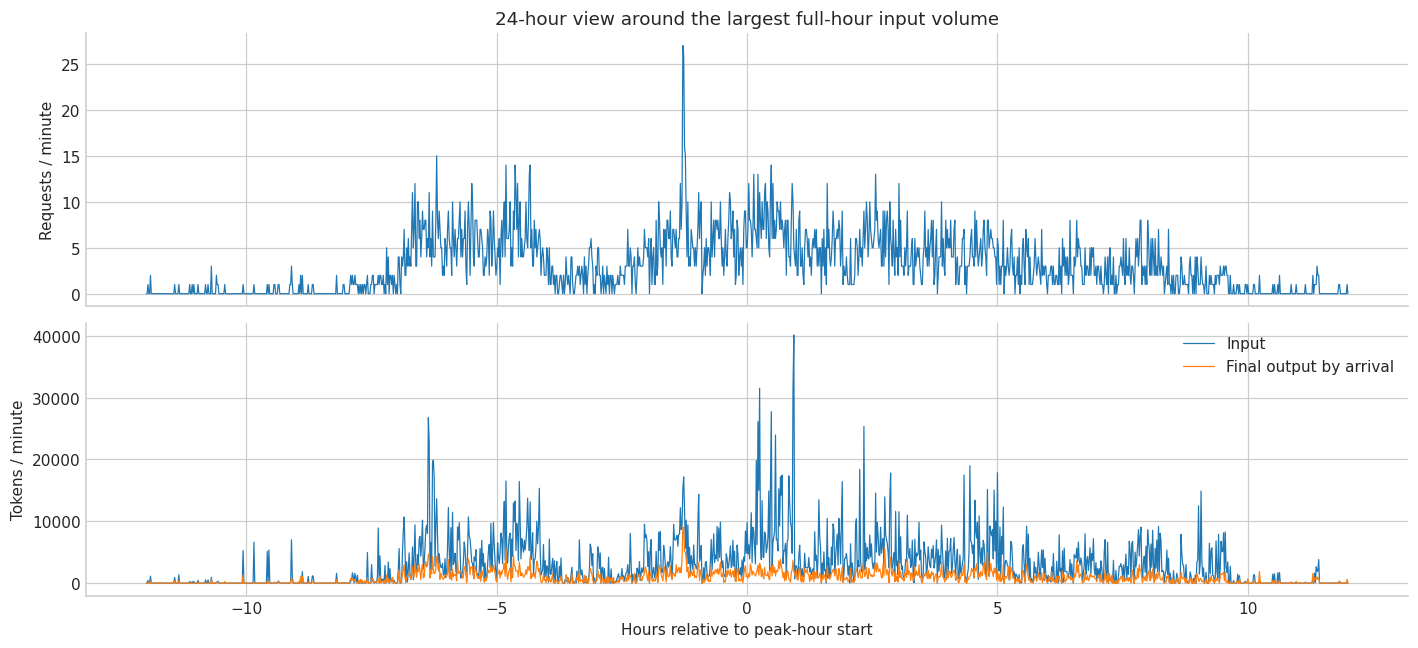

,block_id,requests,input_tokens,arrival_final_output_tokens,completed_output_tokens,timestamp,full_observation,elapsed_days
2176,7576,455,607194,106006,"105,752.0000",27273600,True,90.6654
2367,7767,432,548776,124778,"123,930.0000",27961200,True,98.6237
2199,7599,471,490868,145124,"144,246.0000",27356400,True,91.6237
2151,7551,490,463310,137320,"137,903.0000",27183600,True,89.6237
2027,7427,435,461516,131024,"132,187.0000",26737200,True,84.4571
2150,7550,462,452478,131452,"130,869.0000",27180000,True,89.5821
597,5997,125,442477,59593,"62,563.0000",21589200,True,24.8737
2368,7768,465,440351,131640,"131,919.0000",27964800,True,98.6654
2037,7437,250,432457,60191,"59,944.0000",26773200,True,84.8737
2147,7547,426,423477,130482,"130,482.0000",27169200,True,89.4571


,block_id,requests,input_tokens,arrival_final_output_tokens,completed_output_tokens,timestamp,full_observation,elapsed_days
2176,7576,455,607194,106006,"105,752.0000",27273600,True,90.6654
2367,7767,432,548776,124778,"123,930.0000",27961200,True,98.6237
2199,7599,471,490868,145124,"144,246.0000",27356400,True,91.6237
2151,7551,490,463310,137320,"137,903.0000",27183600,True,89.6237
2027,7427,435,461516,131024,"132,187.0000",26737200,True,84.4571
2150,7550,462,452478,131452,"130,869.0000",27180000,True,89.5821
597,5997,125,442477,59593,"62,563.0000",21589200,True,24.8737
2368,7768,465,440351,131640,"131,919.0000",27964800,True,98.6654
2037,7437,250,432457,60191,"59,944.0000",26773200,True,84.8737
2147,7547,426,423477,130482,"130,482.0000",27169200,True,89.4571


In [5]:
COLS = ['requests', 'input_tokens', 'arrival_final_output_tokens', 'completed_output_tokens']
aggregates = {}
resolution_records = []
for seconds, name in [(60, '1min'), (300, '5min'), (600, '10min'), (3600, '1hour')]:
    block = minute.groupby(minute['timestamp'] // seconds)[COLS].sum().rename_axis('block_id').reset_index()
    block['timestamp'] = block['block_id'] * seconds
    block['full_observation'] = block['timestamp'].ge(amin) & (block['timestamp'] + seconds).le(amax)
    aggregates[name] = block
    save_table(block, f'04_series_{name}', show=False)
    for col in COLS:
        vals = block.loc[block['full_observation'], col]
        resolution_records.append({'resolution': name, 'measure': col, 'full_bins': len(vals),
            'zero_pct': float(vals.eq(0).mean() * 100), 'mean': float(vals.mean()),
            'median': float(vals.median()), 'p95': float(vals.quantile(.95)),
            'p99': float(vals.quantile(.99)), 'max': float(vals.max())})
resolution_summary = save_table(pd.DataFrame(resolution_records), '04_resolution_summary', rows=20)
hourly = aggregates['1hour'].loc[lambda x: x['full_observation']].copy()
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
x = (hourly['timestamp'] - amin) / 86400
for ax, col, label in zip(axes, ['requests', 'input_tokens', 'arrival_final_output_tokens'],
                         ['Requests / hour', 'Input tokens / hour', 'Final output tokens / arrival hour']):
    ax.plot(x, hourly[col], linewidth=.7)
    ax.set(ylabel=label)
axes[-1].set_xlabel('Elapsed days since first conversation request')
axes[0].set_title('Conversation time series: fully observed 1-hour bins')
save_fig(fig, '04_hourly_timeseries')

peak_hour = float(hourly.loc[hourly['input_tokens'].idxmax(), 'timestamp'])
zoom = minute.loc[minute['timestamp'].between(peak_hour - 12 * 3600, peak_hour + 12 * 3600)].copy()
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
zx = (zoom['timestamp'] - peak_hour) / 3600
axes[0].plot(zx, zoom['requests'], linewidth=.8)
axes[0].set(ylabel='Requests / minute', title='24-hour view around the largest full-hour input volume')
axes[1].plot(zx, zoom['input_tokens'], label='Input', linewidth=.8)
axes[1].plot(zx, zoom['arrival_final_output_tokens'], label='Final output by arrival', linewidth=.8)
axes[1].set(xlabel='Hours relative to peak-hour start', ylabel='Tokens / minute'); axes[1].legend()
save_fig(fig, '04_peak_zoom')
peaks = hourly.nlargest(10, 'input_tokens').copy()
peaks['elapsed_days'] = (peaks['timestamp'] - amin) / 86400
save_table(peaks, '04_top_input_hours', rows=10)

## 5. 토큰 길이 분포·0·극단값

평균뿐 아니라 중앙값(절반이 이 값 이하), 상위 5%·1% 경계와 최댓값을 봅니다.
긴 꼬리를 보기 위해 `log(1 + 값)` 축을 사용하고, 원본 값은 삭제·잘라내지 않습니다.
토큰 길이는 텍스트의 의미·주제를 직접 나타내지 않습니다.

,field,count,mean,std,min,1%,25%,50%,75%,90%,95%,99%,99.9%,max
0,Request tokens,"233,617.0000",952.6386,"1,369.8979",0.0000,10.0000,150.0000,517.0000,"1,300.0000","2,354.0000","3,162.0000","5,629.8400","13,465.7680","71,197.0000"
1,Response tokens,"233,617.0000",271.9815,269.7258,0.0000,1.0000,55.0000,187.0000,412.0000,669.0000,805.0000,"1,067.0000","1,850.0000","2,049.0000"
2,Total tokens,"233,617.0000","1,224.6201","1,507.6628",0.0000,20.0000,322.0000,745.0000,"1,648.0000","2,866.4000","3,787.0000","6,314.8400","14,272.0000","71,253.0000"


,Model,rows,zero_input,zero_output,all_tokens_zero,elapsed_zero,elapsed_ge_300,all_tokens_zero_pct
0,ChatGPT,158117,839,839,839,29898,257,0.5306
1,GPT-4,75500,1017,1017,1017,3881,148,1.3470


,Model,Request tokens_count,Request tokens_mean,Request tokens_median,Request tokens_max,Response tokens_count,Response tokens_mean,Response tokens_median,Response tokens_max
0,ChatGPT,158117,784.6759,439.0000,14320,158117,198.0138,144.0000,2048
1,GPT-4,75500,"1,304.3968",773.0000,71197,75500,426.8895,420.0000,2049


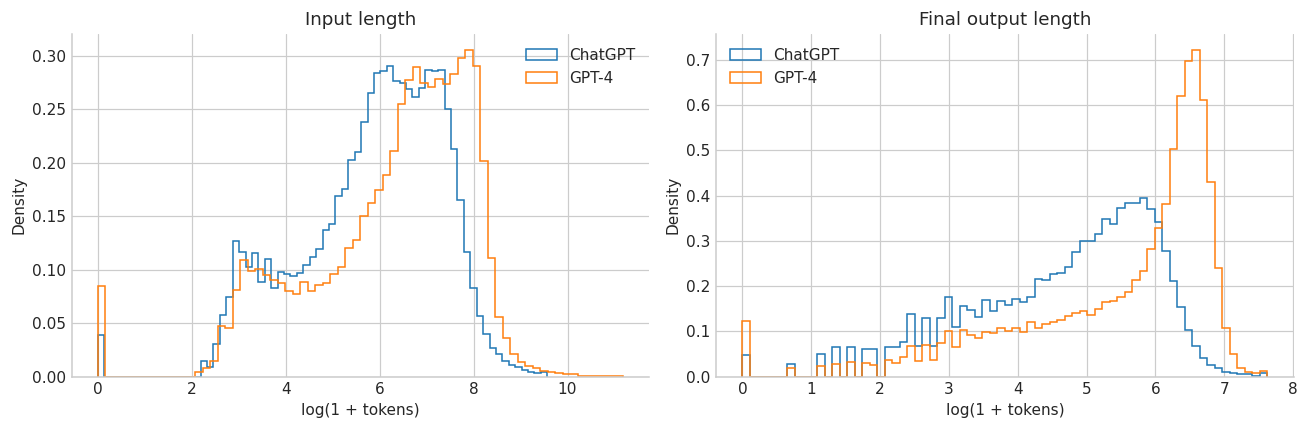

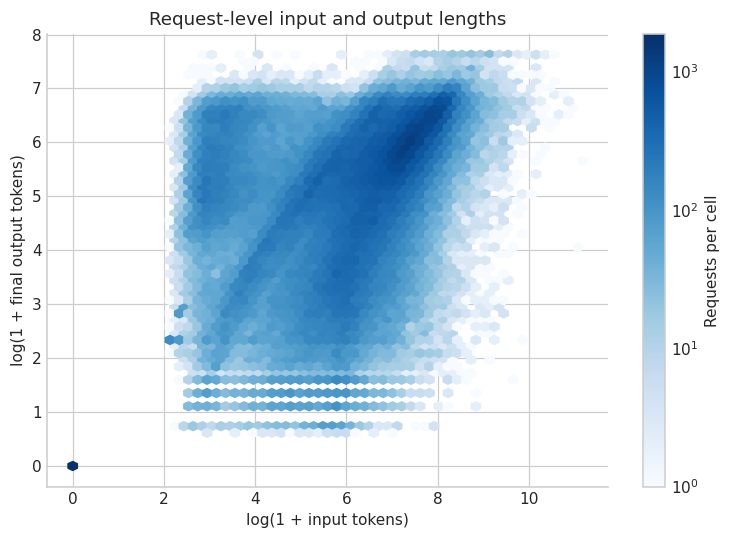

,Timestamp,Model,Request tokens,Response tokens,Elapsed time
4096069,"26,932,656.0000",GPT-4,71197,56,4
4096021,"26,932,623.0000",GPT-4,70907,272,20
5230007,"28,375,228.0000",GPT-4,54855,880,35
5229954,"28,374,939.0000",GPT-4,54055,745,34
5229842,"28,374,394.0000",GPT-4,52344,866,40
3889671,"26,599,808.0000",GPT-4,49731,685,34
3889683,"26,600,034.0000",GPT-4,44322,937,46
3970270,"26,847,076.0000",GPT-4,43009,650,26
3969514,"26,846,430.0000",GPT-4,42317,678,26
1444145,"21,491,309.0000",GPT-4,39959,1184,52


,Timestamp,Model,Request tokens,Response tokens,Elapsed time
4096069,"26,932,656.0000",GPT-4,71197,56,4
4096021,"26,932,623.0000",GPT-4,70907,272,20
5230007,"28,375,228.0000",GPT-4,54855,880,35
5229954,"28,374,939.0000",GPT-4,54055,745,34
5229842,"28,374,394.0000",GPT-4,52344,866,40
3889671,"26,599,808.0000",GPT-4,49731,685,34
3889683,"26,600,034.0000",GPT-4,44322,937,46
3970270,"26,847,076.0000",GPT-4,43009,650,26
3969514,"26,846,430.0000",GPT-4,42317,678,26
1444145,"21,491,309.0000",GPT-4,39959,1184,52


In [6]:
token_distribution = conv.loc[conv['_valid_tokens'], ['Request tokens', 'Response tokens', 'Total tokens']].describe(
    percentiles=[.01, .25, .5, .75, .9, .95, .99, .999]).T.reset_index(names='field')
save_table(token_distribution, '05_token_distribution')
zero_summary = conv.groupby('Model', observed=True).agg(
    rows=('Timestamp', 'size'), zero_input=('Request tokens', lambda s: s.eq(0).sum()),
    zero_output=('Response tokens', lambda s: s.eq(0).sum()),
    all_tokens_zero=('_zero_token_record', 'sum'), elapsed_zero=('_elapsed_zero', 'sum'),
    elapsed_ge_300=('_elapsed_ge_300', 'sum')).reset_index()
zero_summary['all_tokens_zero_pct'] = zero_summary['all_tokens_zero'] / zero_summary['rows'] * 100
save_table(zero_summary, '05_zero_tokens_by_model')
token_by_model = conv.groupby('Model', observed=True)[['Request tokens', 'Response tokens']].agg(
    ['count', 'mean', 'median', 'max']).reset_index()
token_by_model.columns = ['_'.join(filter(None, map(str, col))) if isinstance(col, tuple) else col for col in token_by_model.columns]
save_table(token_by_model, '05_tokens_by_model')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title in zip(axes, ['Request tokens', 'Response tokens'], ['Input length', 'Final output length']):
    for model, group in conv.loc[conv['_valid_tokens']].groupby('Model', observed=True):
        ax.hist(np.log1p(group[col]), bins=70, histtype='step', density=True, label=model)
    ax.set(title=title, xlabel='log(1 + tokens)', ylabel='Density'); ax.legend()
save_fig(fig, '05_token_lengths')
fig, ax = plt.subplots(figsize=(7, 5))
hb = ax.hexbin(np.log1p(valid['Request tokens']), np.log1p(valid['Response tokens']),
               gridsize=55, bins='log', mincnt=1, cmap='Blues')
ax.set(xlabel='log(1 + input tokens)', ylabel='log(1 + final output tokens)', title='Request-level input and output lengths')
fig.colorbar(hb, ax=ax, label='Requests per cell')
save_fig(fig, '05_input_output_relation')
top_requests = valid.nlargest(10, 'Request tokens')[['Timestamp', 'Model', 'Request tokens', 'Response tokens', 'Elapsed time']].copy()
save_table(top_requests, '05_top_input_requests')

## 6. 대화 ID 품질·반복 구조

유효 ID는 비어 있거나 지정한 대체값이 아닌 ID입니다. UUID 형식은 별도로 확인하되, 형식만으로 유효성을 단정하지 않습니다.
대화별 횟수·관측 기간은 **파일 전체를 본 사후 설명 통계**입니다. 미래 예측의 입력에 그대로 사용하면 안 됩니다.
관측 기간의 양 끝 때문에 대화 시작·종료가 잘렸을 수 있으며, ID가 오래 유지된다고 실제 대화가 계속 진행 중이었다는 뜻은 아닙니다.

,valid_id_rows,invalid_id_rows,id_whitespace_rows,uuid_format_rows,unique_sessions,single_request_sessions,repeat_sessions,repeat_sessions_pct,rows_in_repeat_sessions_pct,max_requests_per_session,largest_session_row_share_pct,mixed_model_sessions,mixed_model_sessions_pct,observed_span_over_24h_sessions,same_session_same_timestamp_extra_rows,model_switches
0,233617,0,0,233617,55920,19834,36086,64.5315,91.5100,436,0.1866,3950,7.0637,1087,0,5190


,measure,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
0,requests,"55,920.0000",4.1777,7.1289,1.0000,1.0000,2.0000,4.0000,9.0000,14.0000,31.0000,436.0000
1,observed_span_seconds,"55,920.0000","18,141.6815","191,248.7251",0.0000,0.0000,121.0000,"1,837.0000","11,812.5000","25,132.4000","312,894.2500","7,864,148.0000"
2,model_count,"55,920.0000",1.0706,0.2562,1.0000,1.0000,1.0000,1.0000,1.0000,2.0000,2.0000,2.0000


,requests_per_session,sessions
0,1,19834
1,2,11389
2,3,6665
3,4,4268
4,5,2874
5,6,2072
6,7,1577
7,8,1152
8,9,989
9,10,721


,statistic,gap_seconds
0,count,"177,697.0000"
1,mean,"5,709.0600"
2,std,"75,546.6997"
3,min,1.0000
4,1%,8.0000
5,25%,42.0000
6,50%,131.0000
7,75%,533.0000
8,90%,"2,340.0000"
9,95%,"7,262.2000"


,threshold_seconds,observed_followup_gaps_le_threshold_pct
0,60,33.0754
1,300,66.1030
2,600,76.6862
3,900,81.6221
4,1800,88.1163
5,3600,92.3809
6,86400,99.1047


이 비율의 분모는 **후속 요청이 실제 관측된 요청 쌍**입니다. 모든 요청의 재방문 확률로 해석하지 않습니다.

,_turn,requests,median_input,p25_input,p75_input,median_input_change
0,1,55920,44.0000,23.0000,113.0000,NaN
1,2,36086,312.0000,162.0000,627.0000,231.0000
2,3,24697,597.0000,315.0000,"1,113.0000",254.0000
3,4,18032,888.0000,474.0000,"1,594.0000",263.0000
4,5,13764,"1,178.0000",627.7500,"2,058.0000",267.0000
5,6,10890,"1,188.5000",612.0000,"2,053.0000",14.0000
6,7,8818,"1,211.0000",614.0000,"2,073.0000",26.0000
7,8,7241,"1,230.0000",619.0000,"2,082.0000",21.0000
8,9,6089,"1,237.0000",603.0000,"2,102.0000",17.0000
9,10,5100,"1,242.0000",601.7500,"2,079.2500",18.0000


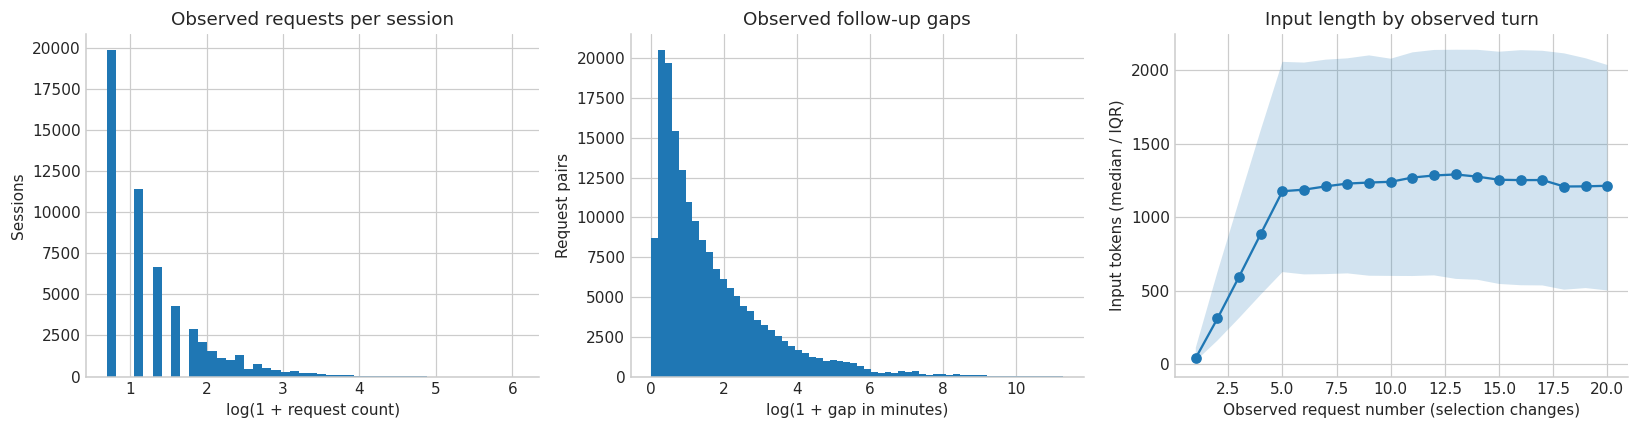

In [7]:
session_rows = conv.loc[conv['_valid_id'] & conv['_valid_time']].sort_values(['Session ID', 'Timestamp'], kind='stable').copy()
session_rows['_gap_seconds'] = session_rows.groupby('Session ID', sort=False)['Timestamp'].diff()
session_rows['_input_delta'] = session_rows.groupby('Session ID', sort=False)['Request tokens'].diff()
session_rows['_turn'] = session_rows.groupby('Session ID', sort=False).cumcount() + 1
session_rows['_prev_model'] = session_rows.groupby('Session ID', sort=False, observed=True)['Model'].shift()
session_rows['_model_switch'] = session_rows['_prev_model'].notna() & session_rows['Model'].ne(session_rows['_prev_model'])
sessions = session_rows.groupby('Session ID', sort=False).agg(
    requests=('Timestamp', 'size'), first_timestamp=('Timestamp', 'min'), last_timestamp=('Timestamp', 'max'),
    model_count=('Model', 'nunique'), input_tokens=('Request tokens', 'sum'),
    zero_token_requests=('_zero_token_record', 'sum'))
sessions['observed_span_seconds'] = sessions['last_timestamp'] - sessions['first_timestamp']
repeat = sessions['requests'].ge(2)
uuid_ok = conv.loc[conv['_valid_id'], 'Session ID'].str.fullmatch(
    r'[0-9a-fA-F]{8}-[0-9a-fA-F]{4}-[0-9a-fA-F]{4}-[0-9a-fA-F]{4}-[0-9a-fA-F]{12}')
session_quality = {
    'valid_id_rows': int(conv['_valid_id'].sum()), 'invalid_id_rows': int((~conv['_valid_id']).sum()),
    'id_whitespace_rows': id_whitespace, 'uuid_format_rows': int(uuid_ok.sum()),
    'unique_sessions': len(sessions), 'single_request_sessions': int((~repeat).sum()),
    'repeat_sessions': int(repeat.sum()), 'repeat_sessions_pct': float(repeat.mean() * 100),
    'rows_in_repeat_sessions_pct': float(sessions.loc[repeat, 'requests'].sum() / len(session_rows) * 100),
    'max_requests_per_session': int(sessions['requests'].max()),
    'largest_session_row_share_pct': float(sessions['requests'].max() / len(session_rows) * 100),
    'mixed_model_sessions': int(sessions['model_count'].gt(1).sum()),
    'mixed_model_sessions_pct': float(sessions['model_count'].gt(1).mean() * 100),
    'observed_span_over_24h_sessions': int(sessions['observed_span_seconds'].gt(86400).sum()),
    'same_session_same_timestamp_extra_rows': int(session_rows.duplicated(['Session ID', 'Timestamp']).sum()),
    'model_switches': int(session_rows['_model_switch'].sum()),
}
save_table(pd.DataFrame([session_quality]), '06_session_quality')
session_distribution = sessions[['requests', 'observed_span_seconds', 'model_count']].describe(
    percentiles=[.25, .5, .75, .9, .95, .99]).T.reset_index(names='measure')
save_table(session_distribution, '06_session_distribution')
session_size_counts = sessions['requests'].value_counts().sort_index().rename_axis('requests_per_session').reset_index(name='sessions')
save_table(session_size_counts, '06_session_size_counts', rows=12)
gaps = session_rows['_gap_seconds'].dropna()
gap_distribution = gaps.describe(percentiles=[.01, .25, .5, .75, .9, .95, .99]).to_frame('gap_seconds').reset_index(names='statistic')
save_table(gap_distribution, '06_followup_gap_distribution')
gap_thresholds = pd.DataFrame({'threshold_seconds': [60, 300, 600, 900, 1800, 3600, 86400]})
gap_thresholds['observed_followup_gaps_le_threshold_pct'] = [float(gaps.le(v).mean() * 100) for v in gap_thresholds['threshold_seconds']]
save_table(gap_thresholds, '06_followup_gap_thresholds')
display(Markdown('이 비율의 분모는 **후속 요청이 실제 관측된 요청 쌍**입니다. 모든 요청의 재방문 확률로 해석하지 않습니다.'))
turn_lengths = session_rows.loc[session_rows['_turn'].le(20)].groupby('_turn').agg(
    requests=('Timestamp', 'size'), median_input=('Request tokens', 'median'),
    p25_input=('Request tokens', lambda s: s.quantile(.25)),
    p75_input=('Request tokens', lambda s: s.quantile(.75)),
    median_input_change=('_input_delta', 'median')).reset_index()
save_table(turn_lengths, '06_input_length_by_observed_turn', rows=10)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(np.log1p(sessions['requests']), bins=45)
axes[0].set(title='Observed requests per session', xlabel='log(1 + request count)', ylabel='Sessions')
axes[1].hist(np.log1p(gaps / 60), bins=60)
axes[1].set(title='Observed follow-up gaps', xlabel='log(1 + gap in minutes)', ylabel='Request pairs')
axes[2].plot(turn_lengths['_turn'], turn_lengths['median_input'], marker='o')
axes[2].fill_between(turn_lengths['_turn'], turn_lengths['p25_input'], turn_lengths['p75_input'], alpha=.2)
axes[2].set(title='Input length by observed turn', xlabel='Observed request number (selection changes)', ylabel='Input tokens (median / IQR)')
save_fig(fig, '06_sessions_and_followups')

## 7. 응답시간·완료시각·미완료 요청

`완료시각 = Timestamp + Elapsed time`을 사용합니다. 0초가 실패나 결측이라는 근거는 없으므로 유지합니다.
토큰 0 또는 300초 이상인 기록의 원인은 데이터만으로 확정하지 않고 관측 사실만 보고합니다.
매 1분 경계 `t`에서 **도착 < t 이고 완료 >= t**인 요청을 미완료(최종 출력 이용 불가)로 셉니다.
이는 GPU가 실제 처리 중인 작업 수를 직접 측정한 값은 아닙니다.

,statistic,elapsed_seconds
0,count,"233,617.0000"
1,mean,7.0031
2,std,17.6572
3,min,0.0000
4,25%,1.0000
5,50%,3.0000
6,75%,7.0000
7,90%,16.0000
8,95%,22.0000
9,99%,61.0000


,zero_elapsed_rows,zero_elapsed_pct,positive_output_with_zero_elapsed_rows,elapsed_ge_300_rows,elapsed_ge_300_zero_token_rows,max_elapsed_seconds,zero_output_rows,all_tokens_zero_rows,zero_output_positive_input_rows,completion_before_arrival_rows
0,33779,14.4591,32651,405,387,714.0000,1856,1856,0,0


,all_tokens_zero,elapsed_positive,elapsed_zero
0,False,199110,32651
1,True,728,1128


,statistic,pending_requests
0,count,"158,397.0000"
1,mean,0.1729
2,std,0.5193
3,min,0.0000
4,50%,0.0000
5,90%,1.0000
6,95%,1.0000
7,99%,2.0000
8,max,16.0000


완전 관측 분 경계 중 미완료 요청이 있는 비율: 13.90%


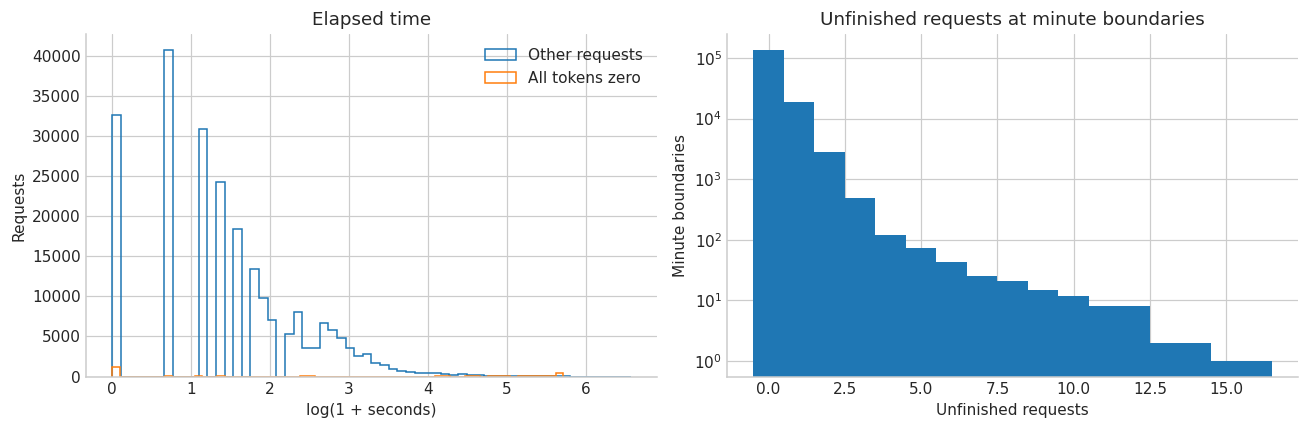

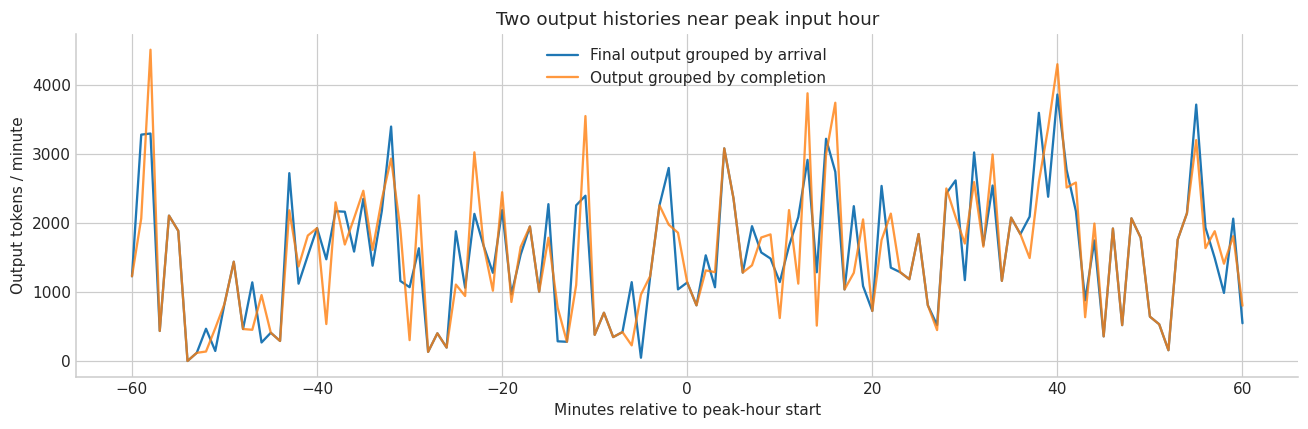

In [8]:
elapsed_distribution = conv.loc[conv['_valid_elapsed'], 'Elapsed time'].describe(
    percentiles=[.25, .5, .75, .9, .95, .99, .999]).to_frame('elapsed_seconds').reset_index(names='statistic')
save_table(elapsed_distribution, '07_elapsed_distribution')
zero_positive = int((conv['Elapsed time'].eq(0) & conv['Response tokens'].gt(0)).sum())
elapsed_quality = {
    'zero_elapsed_rows': int(conv['_elapsed_zero'].sum()),
    'zero_elapsed_pct': float(conv['_elapsed_zero'].mean() * 100),
    'positive_output_with_zero_elapsed_rows': zero_positive,
    'elapsed_ge_300_rows': int(conv['_elapsed_ge_300'].sum()),
    'elapsed_ge_300_zero_token_rows': int((conv['_elapsed_ge_300'] & conv['_zero_token_record']).sum()),
    'max_elapsed_seconds': float(conv['Elapsed time'].max()),
    'zero_output_rows': int(conv['Response tokens'].eq(0).sum()),
    'all_tokens_zero_rows': int(conv['_zero_token_record'].sum()),
    'zero_output_positive_input_rows': int((conv['Response tokens'].eq(0) & conv['Request tokens'].gt(0)).sum()),
    'completion_before_arrival_rows': int(conv['_completion'].lt(conv['Timestamp']).sum()),
}
save_table(pd.DataFrame([elapsed_quality]), '07_elapsed_quality')
zero_elapsed_crosstab = pd.crosstab(conv['_zero_token_record'], conv['_elapsed_zero']).rename_axis('all_tokens_zero').reset_index()
zero_elapsed_crosstab.columns = ['all_tokens_zero', 'elapsed_positive', 'elapsed_zero']
save_table(zero_elapsed_crosstab, '07_zero_token_elapsed_cross')

complete_ok = conv['_valid_time'] & conv['_valid_elapsed']
arrivals_sorted = np.sort(conv.loc[complete_ok, 'Timestamp'].to_numpy())
completions_sorted = np.sort(conv.loc[complete_ok, '_completion'].to_numpy())
ticks = minute['timestamp'].to_numpy()
pending = np.searchsorted(arrivals_sorted, ticks, side='left') - np.searchsorted(completions_sorted, ticks, side='left')
assert pending.min() >= 0
minute['pending_requests'] = pending
pending_eligible = minute['full_observation']
pending_summary = minute.loc[pending_eligible, 'pending_requests'].describe(percentiles=[.5, .9, .95, .99]).to_frame('pending_requests').reset_index(names='statistic')
save_table(pending_summary, '07_pending_request_distribution')
pending_minutes_pct = float(minute.loc[pending_eligible, 'pending_requests'].gt(0).mean() * 100)
print(f'완전 관측 분 경계 중 미완료 요청이 있는 비율: {pending_minutes_pct:.2f}%')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, group in conv.groupby('_zero_token_record', observed=True):
    axes[0].hist(np.log1p(group.loc[group['_valid_elapsed'], 'Elapsed time']), bins=60,
                 histtype='step', label='All tokens zero' if label else 'Other requests')
axes[0].set(title='Elapsed time', xlabel='log(1 + seconds)', ylabel='Requests'); axes[0].legend()
axes[1].hist(minute.loc[pending_eligible, 'pending_requests'], bins=np.arange(-.5, int(pending.max()) + 1.5, 1))
axes[1].set(title='Unfinished requests at minute boundaries', xlabel='Unfinished requests', ylabel='Minute boundaries', yscale='log')
save_fig(fig, '07_elapsed_and_pending')
completion_comparison = minute.loc[minute['full_observation'], ['timestamp', 'arrival_final_output_tokens', 'completed_output_tokens']].copy()
completion_comparison['difference'] = completion_comparison['completed_output_tokens'] - completion_comparison['arrival_final_output_tokens']
save_table(completion_comparison, '07_arrival_vs_completion_output', show=False)
fig, ax = plt.subplots(figsize=(12, 4))
z = completion_comparison.loc[completion_comparison['timestamp'].between(peak_hour - 3600, peak_hour + 3600)]
ax.plot((z['timestamp'] - peak_hour) / 60, z['arrival_final_output_tokens'], label='Final output grouped by arrival')
ax.plot((z['timestamp'] - peak_hour) / 60, z['completed_output_tokens'], label='Output grouped by completion', alpha=.8)
ax.set(title='Two output histories near peak input hour', xlabel='Minutes relative to peak-hour start', ylabel='Output tokens / minute'); ax.legend()
save_fig(fig, '07_output_time_definitions')

## 8. 시간 패턴·자기상관·변수 관계

시간대는 원본 상대 초의 하루 중 시각을 사용합니다. 각 시간대의 실제 관측 분 수로 나눕니다.
자기상관은 **과거 값과 현재 값이 함께 움직이는 정도**이며 1분~7일 지연을 탐색합니다. 수집 연속성 가정이 깨지면 해석도 달라집니다.
활동 대화 수는 각 1분 경계 `t`의 `[t-창, t)`에 요청이 있었던 유효 ID 수입니다.
대화별 활동 구간을 합쳐 중복 계산을 막고, 미래 정보는 활동 수 계산에 사용하지 않습니다.
최근 5·10분 이력과 **다음 10분 누적 수요**의 관계를 사후 탐색합니다. 5·15·30분 활동 대화 창은 과거 입력이므로 유지합니다.
예측 시점은 1분 간격이며, 60분의 완전한 과거와 10분의 완전한 미래를 확보한 시점만 사용합니다. 출력 목표는 해당 10분에 도착한 요청의 최종 출력 합계로, 구간 종료 후 완료될 출력도 포함합니다.
기존 5분과 새 10분 목표의 0 비율·분포는 **동일한 적격 시점**에서 비교합니다. 후속 요청 간격의 5·10분 이내 비율도 함께 확인합니다. 이는 10분 목표의 특성을 설명하는 근거이며, 최적 예측 기간이나 모델 성능 우월성을 입증하지 않습니다.
전체 기간을 이미 탐색했으므로 최종 평가 구간을 설계 과정에서 전혀 보지 않은 자료로 간주하지 않습니다.

,hour_of_day,observed_minutes,mean_requests,median_requests,mean_input_tokens,mean_arrival_final_output_tokens,empty_minute_pct
0,0,6598,0.8136,0.0000,970.0352,253.6511,50.8942
1,1,6600,0.4438,0.0000,550.0682,139.0397,68.5758
2,2,6600,0.2938,0.0000,341.1568,87.1456,78.7576
3,3,6600,0.1585,0.0000,166.0403,46.3612,87.3182
4,4,6600,0.0892,0.0000,97.8688,29.6386,92.3485
5,5,6600,0.0676,0.0000,67.5271,19.0483,94.0303
6,6,6600,0.0800,0.0000,89.9402,25.1039,93.0455
7,7,6600,0.1395,0.0000,117.7009,35.0567,89.1515
8,8,6600,0.4006,0.0000,309.0870,105.1556,73.1667
9,9,6600,1.9297,1.0000,"1,347.3458",458.4735,31.7273


,lag_minutes,requests,input_tokens,arrival_final_output_tokens
1,1,0.6631,0.4222,0.5125
2,2,0.6361,0.4085,0.4976
3,3,0.6175,0.3933,0.4745
5,5,0.6001,0.3691,0.4593
10,10,0.5802,0.3413,0.4386
15,15,0.5654,0.3233,0.4236
30,30,0.5282,0.2904,0.3942
60,60,0.4595,0.2510,0.3485
1440,1440,0.4742,0.2547,0.3591
10080,10080,0.4524,0.2356,0.3291


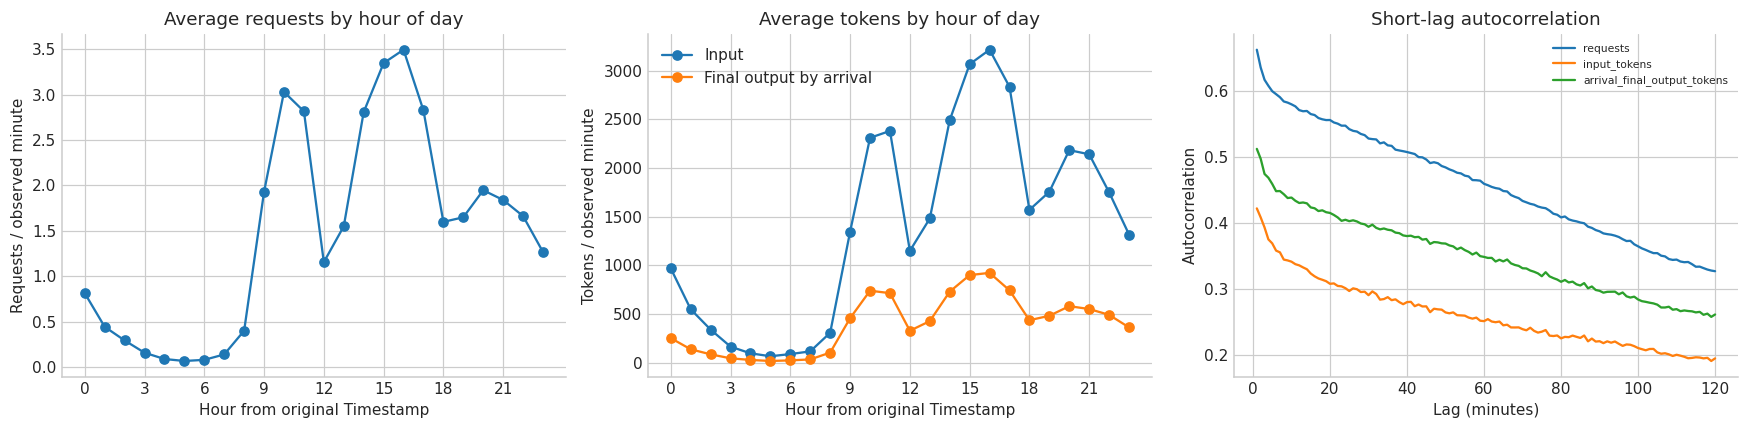

,measure,count,mean,std,min,50%,90%,95%,99%,max
0,active_sessions_5min,"158,328.0000",4.7477,5.3768,0.0000,3.0000,12.0000,16.0000,23.0000,54.0000
1,active_sessions_15min,"158,328.0000",10.9973,11.8041,0.0000,7.0000,27.0000,35.0000,52.0000,82.0000
2,active_sessions_30min,"158,328.0000",18.7477,19.6791,0.0000,12.0000,46.0000,58.0000,86.0000,123.0000


,horizon_minutes,measure,eligible_timestamps,first_timestamp,last_timestamp,zero_pct,mean,median,p95,p99,max
0,5,requests,158328,19443720,28943340,22.2026,7.3763,4.0000,26.0000,38.0000,94.0000
1,5,input_tokens,158328,19443720,28943340,22.3277,"7,026.8753","3,532.0000","26,021.6500","41,323.9200","178,297.0000"
2,5,final_output_tokens,158328,19443720,28943340,22.3277,"2,006.2485","1,143.0000","7,090.0000","10,864.7300","31,937.0000"
3,10,requests,158328,19443720,28943340,15.7123,14.7528,9.0000,50.0000,74.0000,140.0000
4,10,input_tokens,158328,19443720,28943340,15.8146,"14,054.0477","7,950.0000","49,409.6500","76,069.1900","193,983.0000"
5,10,final_output_tokens,158328,19443720,28943340,15.8146,"4,012.5758","2,479.0000","13,580.6500","20,764.0000","44,210.0000"


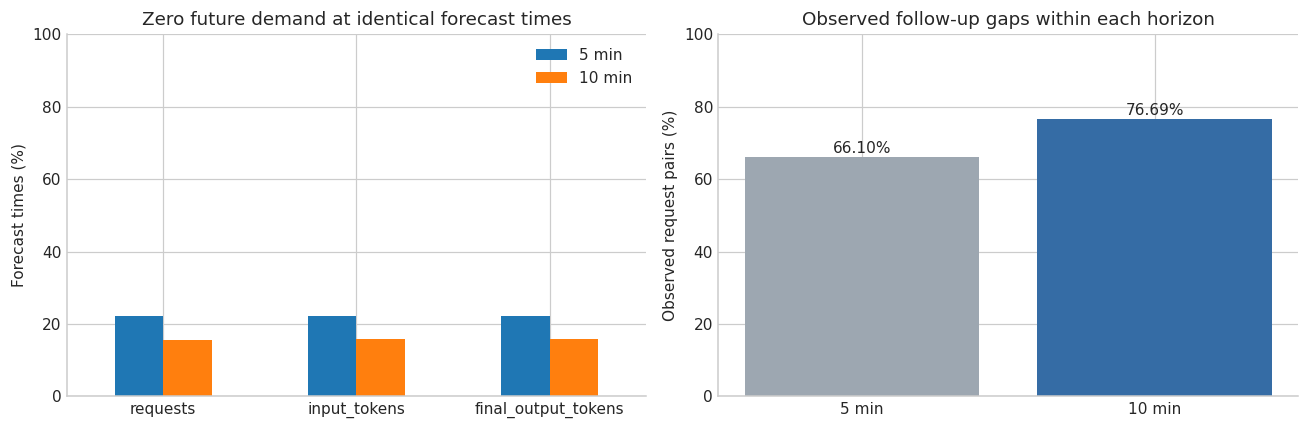

후속 요청 비율의 분모는 **후속 요청이 실제 관측된 쌍**입니다. 모든 요청의 재방문 확률이나 모델 성능이 아닙니다.

,measure,past5_requests,past5_input_tokens,past5_completed_output_tokens,past10_requests,past10_input_tokens,past10_completed_output_tokens,active_sessions_5min,active_sessions_15min,active_sessions_30min,next10_input_tokens,next10_final_output_tokens
0,past5_requests,1.0000,0.9218,0.9348,0.9601,0.8876,0.9086,0.9783,0.9227,0.9000,0.8216,0.8322
1,past5_input_tokens,0.9218,1.0000,0.9342,0.8920,0.9375,0.9018,0.9029,0.8487,0.8292,0.8062,0.7917
2,past5_completed_output_tokens,0.9348,0.9342,1.0000,0.9064,0.8956,0.9431,0.9277,0.8781,0.8560,0.8073,0.8144
3,past10_requests,0.9601,0.8920,0.9064,1.0000,0.9301,0.9499,0.9509,0.9608,0.9381,0.8431,0.8542
4,past10_input_tokens,0.8876,0.9375,0.8956,0.9301,1.0000,0.9495,0.8786,0.8872,0.8680,0.8305,0.8165
5,past10_completed_output_tokens,0.9086,0.9018,0.9431,0.9499,0.9495,1.0000,0.9091,0.9238,0.9016,0.8354,0.8431
6,active_sessions_5min,0.9783,0.9029,0.9277,0.9509,0.8786,0.9091,1.0000,0.9431,0.9202,0.8254,0.8413
7,active_sessions_15min,0.9227,0.8487,0.8781,0.9608,0.8872,0.9238,0.9431,1.0000,0.9782,0.8466,0.8662
8,active_sessions_30min,0.9000,0.8292,0.8560,0.9381,0.8680,0.9016,0.9202,0.9782,1.0000,0.8436,0.8645
9,next10_input_tokens,0.8216,0.8062,0.8073,0.8431,0.8305,0.8354,0.8254,0.8466,0.8436,1.0000,0.9516


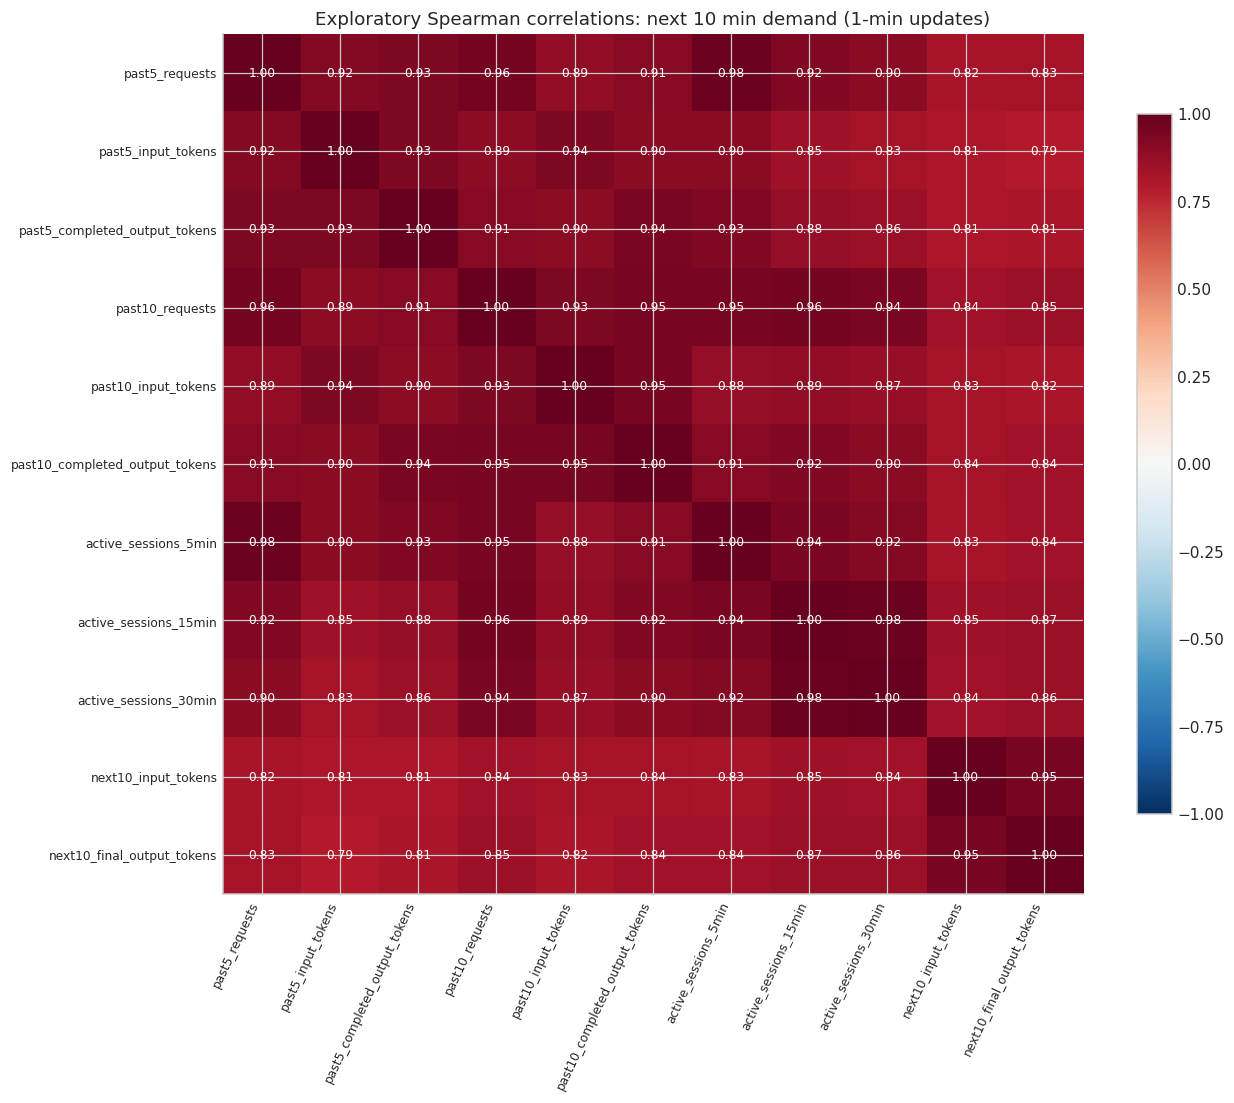

,high_input_hour,hours,mean_requests,median_requests,mean_input_tokens,mean_request_input_length,median_request_input_length
0,False,2506,75.1744,54.0000,"70,620.0694",975.5236,883.8481
1,True,132,341.7424,349.0000,"344,334.9015","1,061.3983",975.8316


상위 5% 구간은 전체 EDA의 **설명용** 기준입니다. 모델 평가에서 사용할 높은 수요 기준은 학습 자료만으로 다시 정해야 합니다.

In [9]:
hour_profile = full_minute.groupby('hour_of_day').agg(
    observed_minutes=('timestamp', 'size'), mean_requests=('requests', 'mean'),
    median_requests=('requests', 'median'), mean_input_tokens=('input_tokens', 'mean'),
    mean_arrival_final_output_tokens=('arrival_final_output_tokens', 'mean'),
    empty_minute_pct=('requests', lambda s: s.eq(0).mean() * 100)).reset_index()
save_table(hour_profile, '08_hour_of_day_profile', rows=24)

def acf_fft(values, max_lag):
    values = np.asarray(values, dtype=float)
    values = values - values.mean()
    if len(values) < 2 or np.dot(values, values) == 0:
        return np.full(max_lag + 1, np.nan)
    corr = signal.fftconvolve(values, values[::-1], mode='full')[len(values) - 1:]
    return corr[:max_lag + 1] / corr[0]

lag_max = min(10080, len(full_minute) - 1)
acf_values = {col: acf_fft(full_minute[col], lag_max) for col in
              ['requests', 'input_tokens', 'arrival_final_output_tokens']}
acf_full = pd.DataFrame({'lag_minutes': np.arange(lag_max + 1), **acf_values})
save_table(acf_full, '08_autocorrelation_all_lags', show=False)
selected_lags = [v for v in [1, 2, 3, 5, 10, 15, 30, 60, 1440, 10080] if v <= lag_max]
save_table(acf_full.loc[acf_full['lag_minutes'].isin(selected_lags)], '08_autocorrelation_selected_lags')
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(hour_profile['hour_of_day'], hour_profile['mean_requests'], marker='o')
axes[0].set(title='Average requests by hour of day', xlabel='Hour from original Timestamp', ylabel='Requests / observed minute', xticks=range(0, 24, 3))
axes[1].plot(hour_profile['hour_of_day'], hour_profile['mean_input_tokens'], marker='o', label='Input')
axes[1].plot(hour_profile['hour_of_day'], hour_profile['mean_arrival_final_output_tokens'], marker='o', label='Final output by arrival')
axes[1].set(title='Average tokens by hour of day', xlabel='Hour from original Timestamp', ylabel='Tokens / observed minute', xticks=range(0, 24, 3)); axes[1].legend()
for col, values in acf_values.items():
    axes[2].plot(np.arange(1, 121), values[1:121], label=col)
axes[2].set(title='Short-lag autocorrelation', xlabel='Lag (minutes)', ylabel='Autocorrelation'); axes[2].legend(fontsize=7)
save_fig(fig, '08_time_patterns')

def active_counts_by_window(sorted_sessions, boundaries, window_seconds):
    delta = np.zeros(len(boundaries) + 1, dtype=np.int64)
    for _, group in sorted_sessions.groupby('Session ID', sort=False):
        times = group['Timestamp'].to_numpy()
        starts = np.searchsorted(boundaries, times, side='right')
        stops = np.searchsorted(boundaries, times + window_seconds, side='right')
        current_start, current_stop = None, None
        for left, right in zip(starts, stops):
            if left >= right or left >= len(boundaries):
                continue
            if current_start is None:
                current_start, current_stop = int(left), int(right)
            elif left <= current_stop:
                current_stop = max(current_stop, int(right))
            else:
                delta[current_start] += 1; delta[current_stop] -= 1
                current_start, current_stop = int(left), int(right)
        if current_start is not None:
            delta[current_start] += 1; delta[current_stop] -= 1
    return np.cumsum(delta[:-1])

for minutes in [5, 15, 30]:
    minute[f'active_sessions_{minutes}min'] = active_counts_by_window(session_rows, ticks, minutes * 60)
# 경계 검증: [t-window, t) 범위를 직접 계산한 값과 비교합니다.
for ix in np.linspace(0, len(minute) - 1, 9, dtype=int):
    t = ticks[ix]
    for minutes in [5, 15, 30]:
        direct = session_rows.loc[session_rows['Timestamp'].ge(t - minutes * 60) & session_rows['Timestamp'].lt(t), 'Session ID'].nunique()
        assert minute.iloc[ix][f'active_sessions_{minutes}min'] == direct
assert (minute['active_sessions_5min'] <= minute['active_sessions_15min']).all()
assert (minute['active_sessions_15min'] <= minute['active_sessions_30min']).all()

# 5분은 이전 목표와의 비교용이며, 주 예측 목표는 FORECAST_MINUTES입니다.
comparison_horizons = sorted({5, FORECAST_MINUTES})
target_sources = [('requests', 'requests'), ('input_tokens', 'input_tokens'),
                  ('arrival_final_output_tokens', 'final_output_tokens')]

def next_window_sum(values, minutes):
    # 행 t의 [t, t + minutes*60): t의 분을 포함하고 오른쪽 경계를 제외합니다.
    return values.rolling(minutes, min_periods=minutes).sum().shift(-(minutes - 1))

eligible = (minute['timestamp'].ge(amin + HISTORY_MINUTES * 60)
            & (minute['timestamp'] + FORECAST_SECONDS).le(amax))
assert eligible.any()
relation = minute[['timestamp', 'active_sessions_5min', 'active_sessions_15min', 'active_sessions_30min']].copy()
for source_col, target in target_sources:
    for history_minutes in sorted({5, FORECAST_MINUTES}):
        relation[f'past{history_minutes}_{target}'] = minute[source_col].rolling(
            history_minutes, min_periods=history_minutes).sum().shift(1)
    relation[f'next{FORECAST_MINUTES}_{target}'] = next_window_sum(minute[source_col], FORECAST_MINUTES)
for history_minutes in sorted({5, FORECAST_MINUTES}):
    relation[f'past{history_minutes}_completed_output_tokens'] = minute['completed_output_tokens'].rolling(
        history_minutes, min_periods=history_minutes).sum().shift(1)
relation = relation.loc[eligible].copy()
assert not relation.isna().any().any()
assert relation['timestamp'].diff().dropna().eq(FORECAST_STEP_SECONDS).all()
assert relation['timestamp'].ge(amin + HISTORY_MINUTES * 60).all()
assert (relation['timestamp'] + FORECAST_SECONDS).le(amax).all()
save_table(relation, '08_active_sessions_and_demand', show=False)
active_summary = relation[['active_sessions_5min', 'active_sessions_15min', 'active_sessions_30min']].describe(
    percentiles=[.5, .9, .95, .99]).T.reset_index(names='measure')
save_table(active_summary, '08_active_session_distribution')

# 모든 적격 시점의 목표를 원본 이벤트 누적합과 대조합니다. [t, t+H) 경계를 지킵니다.
event_times = valid['Timestamp'].to_numpy()
forecast_ticks = relation['timestamp'].to_numpy()
left = np.searchsorted(event_times, forecast_ticks, side='left')
horizon_records = []
for horizon in comparison_horizons:
    right = np.searchsorted(event_times, forecast_ticks + horizon * 60, side='left')
    for source_col, target in target_sources:
        values = next_window_sum(minute[source_col], horizon).loc[eligible]
        if target == 'requests':
            direct = right - left
        else:
            raw_col = 'Request tokens' if target == 'input_tokens' else 'Response tokens'
            cumulative = np.r_[0, np.cumsum(valid[raw_col].to_numpy(), dtype=np.int64)]
            direct = cumulative[right] - cumulative[left]
        assert np.array_equal(values.to_numpy(), direct), (horizon, target)
        horizon_records.append({
            'horizon_minutes': horizon, 'measure': target,
            'eligible_timestamps': len(values),
            'first_timestamp': int(forecast_ticks[0]), 'last_timestamp': int(forecast_ticks[-1]),
            'zero_pct': float(values.eq(0).mean() * 100), 'mean': float(values.mean()),
            'median': float(values.median()), 'p95': float(values.quantile(.95)),
            'p99': float(values.quantile(.99)), 'max': float(values.max()),
        })

# 예측 시작과 끝에 정확히 도착한 요청으로 반개구간 경계를 별도 검증합니다.
boundary_times = np.array([-1, 0, 59, FORECAST_SECONDS - 1, FORECAST_SECONDS], dtype=np.int64)
boundary_weights = np.array([1, 10, 100, 1000, 10000], dtype=np.int64)
boundary_series = pd.Series(boundary_weights).groupby(boundary_times // 60).sum().reindex(
    np.arange(FORECAST_MINUTES + 1), fill_value=0)
assert next_window_sum(boundary_series, FORECAST_MINUTES).iloc[0] == 1110
assert boundary_weights[(boundary_times >= 0) & (boundary_times < FORECAST_SECONDS)].sum() == 1110
horizon_summary = save_table(pd.DataFrame(horizon_records), '08_forecast_horizon_summary')

# 요청 도착 기준 최종 출력은 예측 구간이 끝나도 아직 확정되지 않을 수 있습니다.
max_completion_by_minute = valid.groupby('_minute')['_completion'].max().reindex(minute_ids, fill_value=0).fillna(0)
latest_target_completion = max_completion_by_minute.rolling(
    FORECAST_MINUTES, min_periods=FORECAST_MINUTES).max().shift(-(FORECAST_MINUTES - 1))
output_needs_later_completion_pct = float((latest_target_completion.to_numpy()[eligible.to_numpy()]
    >= forecast_ticks + FORECAST_SECONDS).mean() * 100)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
zero_comparison = horizon_summary.pivot(index='measure', columns='horizon_minutes', values='zero_pct').reindex(
    ['requests', 'input_tokens', 'final_output_tokens'])
zero_comparison.columns = [f'{h} min' for h in zero_comparison.columns]
zero_comparison.plot.bar(ax=axes[0], rot=0)
axes[0].set(title='Zero future demand at identical forecast times', ylabel='Forecast times (%)', xlabel='', ylim=(0, 100))
followup_coverage = [float(gaps.le(h * 60).mean() * 100) for h in comparison_horizons]
axes[1].bar([f'{h} min' for h in comparison_horizons], followup_coverage, color=['#9da7b1', '#356ca5'])
for i, value in enumerate(followup_coverage):
    axes[1].text(i, value + 1, f'{value:.2f}%', ha='center')
axes[1].set(title='Observed follow-up gaps within each horizon', ylabel='Observed request pairs (%)', ylim=(0, 100))
save_fig(fig, '08_forecast_horizon_comparison')
display(Markdown('후속 요청 비율의 분모는 **후속 요청이 실제 관측된 쌍**입니다. 모든 요청의 재방문 확률이나 모델 성능이 아닙니다.'))

relation_columns = [f'past{h}_{target}' for h in sorted({5, FORECAST_MINUTES})
                    for target in ['requests', 'input_tokens', 'completed_output_tokens']]
relation_columns += ['active_sessions_5min', 'active_sessions_15min', 'active_sessions_30min',
                     f'next{FORECAST_MINUTES}_input_tokens', f'next{FORECAST_MINUTES}_final_output_tokens']
spearman = relation[relation_columns].corr(method='spearman')
save_table(spearman.reset_index(names='measure'), '08_spearman_correlations')
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(spearman, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(np.arange(len(spearman)), spearman.columns, rotation=65, ha='right', fontsize=8)
ax.set_yticks(np.arange(len(spearman)), spearman.index, fontsize=8)
for i in range(len(spearman)):
    for j in range(len(spearman)):
        value = spearman.iloc[i, j]
        ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(value) > .65 else 'black')
ax.set_title(f'Exploratory Spearman correlations: next {FORECAST_MINUTES} min demand (1-min updates)')
fig.colorbar(im, ax=ax, shrink=.8)
save_fig(fig, '08_demand_correlations')

# 피크에서 요청 수와 요청당 입력 길이가 각각 어떠한지 확인합니다.
hourly['mean_input_per_request'] = hourly['input_tokens'].div(hourly['requests'].replace(0, np.nan))
hourly['mean_output_per_request'] = hourly['arrival_final_output_tokens'].div(hourly['requests'].replace(0, np.nan))
peak_threshold = hourly['input_tokens'].quantile(.95)
hourly['high_input_hour'] = hourly['input_tokens'].ge(peak_threshold)
peak_composition = hourly.groupby('high_input_hour').agg(
    hours=('timestamp', 'size'), mean_requests=('requests', 'mean'),
    median_requests=('requests', 'median'), mean_input_tokens=('input_tokens', 'mean'),
    mean_request_input_length=('mean_input_per_request', 'mean'),
    median_request_input_length=('mean_input_per_request', 'median')).reset_index()
save_table(peak_composition, '08_peak_composition')
display(Markdown('상위 5% 구간은 전체 EDA의 **설명용** 기준입니다. 모델 평가에서 사용할 높은 수요 기준은 학습 자료만으로 다시 정해야 합니다.'))

## 결과 요약·전처리 결정·검증

이 단계의 전처리는 자료형 정리, 유효성 표시, 시간순 정렬, 집계입니다. 모델 학습용 최종 특징 선택이나 결측값 대체는 수행하지 않습니다.
원본·중복·토큰 0·긴 응답은 보존합니다. 관측 범위 안의 빈 구간은 연속 수집 가정 아래 집계 0으로 표시하며 실제 수집 누락 여부는 미확정입니다.
세션별 전체 요청 횟수·전체 관측 기간은 EDA용입니다. 모델용 상태는 예측 시점 이전 이력으로 다시 계산해야 합니다.

In [10]:
zero_count = int(conv['_zero_token_record'].sum())
median_input = float(conv['Request tokens'].median())
median_output = float(conv['Response tokens'].median())
gap_median = float(gaps.median())
summary = {
    'raw': {'rows': total_rows, 'columns': len(EXPECTED), 'min_timestamp': all_min,
            'max_timestamp': all_max, 'duplicate_extra_rows': total_duplicates,
            'token_mismatch_rows': total_token_mismatch},
    'conversation': {
        'rows': len(conv), 'share_all_rows_pct': len(conv) / total_rows * 100,
        'duplicate_extra_rows': conv_duplicate_extra,
        'invalid_rows_for_token_timeseries': invalid_for_timeseries,
        'median_input_tokens': median_input, 'median_output_tokens': median_output,
        'mean_input_tokens': float(conv['Request tokens'].mean()),
        'mean_output_tokens': float(conv['Response tokens'].mean()),
        'zero_token_rows': zero_count, 'zero_token_pct': zero_count / len(conv) * 100,
        'total_input_tokens': int(valid['Request tokens'].sum()),
        'total_final_output_tokens': int(valid['Response tokens'].sum()),
    },
    'coverage': coverage, 'sessions': session_quality, 'response': elapsed_quality,
    'observed_followup_gap_median_seconds': gap_median,
    'observed_followup_gap_le_5min_pct': float(gaps.le(300).mean() * 100),
    'observed_followup_gap_le_10min_pct': float(gaps.le(600).mean() * 100),
    'forecast': {
        **manifest['forecast'], 'eligible_timestamps': len(relation),
        'first_timestamp': int(forecast_ticks[0]), 'last_timestamp': int(forecast_ticks[-1]),
        'output_targets_needing_completion_at_or_after_window_end_pct': output_needs_later_completion_pct,
    },
    'forecast_horizon_comparison': horizon_summary.to_dict(orient='records'),
    'minute_boundaries_with_pending_requests_pct': pending_minutes_pct,
    f'exploratory_next{FORECAST_MINUTES}_correlations': {
        col: {target: float(spearman.loc[col, target]) for target in [f'next{FORECAST_MINUTES}_input_tokens', f'next{FORECAST_MINUTES}_final_output_tokens']}
        for col in relation_columns[:-2]
    },
    'validation': {
        'arrival_token_and_request_sums_match_raw': True,
        'active_session_counts_match_direct_windows_at_9_times': True,
        f'next{FORECAST_MINUTES}_targets_match_direct_event_sums_at_all_eligible_times': True,
        'comparison_targets_match_direct_event_sums_at_all_eligible_times': True,
        'forecast_target_half_open_boundaries_checked': True,
        'history_and_future_fully_observed_at_all_eligible_times': True,
        'raw_sha256_unchanged': digest(RAW) == source_hash,
    },
}
assert summary['validation']['raw_sha256_unchanged'], '원본 변경 감지'
primary_horizon = horizon_summary.loc[horizon_summary['horizon_minutes'].eq(FORECAST_MINUTES)].set_index('measure')
old_horizon = horizon_summary.loc[horizon_summary['horizon_minutes'].eq(5)].set_index('measure')
summary_text = f'''# EDA 결과 요약

- **주 예측 목표:** 매 1분마다 앞으로 {FORECAST_MINUTES}분(`[t, t+{FORECAST_SECONDS}초)`)에 도착할 요청의 누적 입력·최종 출력 토큰 두 값. 최종 출력에는 구간 이후 완료되는 응답도 포함합니다.
- **적격 예측 시점:** 과거 {HISTORY_MINUTES}분과 미래 {FORECAST_MINUTES}분이 완전한 {len(relation):,}개 시점. 원본 상대 초 {int(forecast_ticks[0]):,}~{int(forecast_ticks[-1]):,}이며, 학습·평가 분할 전 EDA 표본입니다.


- 전체 {total_rows:,}건 중 대화형 {len(conv):,}건({len(conv)/total_rows*100:.2f}%)을 주 분석 대상으로 사용했습니다.
- 대화형 관측 범위는 약 {(amax-amin)/86400:.2f}일입니다. 완전 관측 1분 구간의 {coverage['empty_full_minutes_pct']:.2f}%에 요청이 없고, 가장 긴 빈 구간은 {coverage['longest_empty_minutes']:,}분입니다. 실제 무요청과 수집 누락은 구분되지 않습니다.
- 대화형에는 완전 중복 {conv_duplicate_extra:,}건, 토큰 시계열 계산에서 제외된 비정상 행 {invalid_for_timeseries:,}건이 있습니다. API와 대화형의 품질 결과는 별도 표를 참고하세요.
- 대화 ID {len(sessions):,}개 중 반복 요청이 있는 대화는 {session_quality['repeat_sessions_pct']:.2f}%이고, 요청의 {session_quality['rows_in_repeat_sessions_pct']:.2f}%가 반복 대화에 속합니다.
- 후속 요청이 관측된 요청 쌍의 간격 중앙값은 {gap_median:.0f}초입니다. 전체 요청의 재방문 확률을 뜻하지는 않습니다.
- 요청당 입력 길이 중앙값은 {median_input:,.0f}토큰, 최종 출력 길이 중앙값은 {median_output:,.0f}토큰입니다.
- 입력·출력·합계가 모두 0인 기록은 {zero_count:,}건({zero_count/len(conv)*100:.2f}%)이며 삭제하지 않았습니다. 원인은 이 데이터만으로 확정할 수 없습니다.
- 응답시간 0초는 {elapsed_quality['zero_elapsed_rows']:,}건이며 그중 {zero_positive:,}건은 출력이 있습니다. 0초를 실패로 보고 삭제하면 안 됩니다.
- 응답시간 최댓값은 {elapsed_quality['max_elapsed_seconds']:,.0f}초입니다. 분 경계의 {pending_minutes_pct:.2f}%에 미완료 요청이 있어 최종 출력 정보를 도착 순간에 이미 안다고 처리하면 안 됩니다.
- {session_quality['mixed_model_sessions']:,}개 대화에서 둘 이상의 모델을 사용했습니다. Session ID에 모델이 고정돼 있다고 가정하지 않습니다.

## 5분에서 10분으로 목표 변경 시 확인한 점

- 같은 적격 시점에서 입력 목표 0 비율은 5분 {old_horizon.loc['input_tokens', 'zero_pct']:.2f}% → 10분 {primary_horizon.loc['input_tokens', 'zero_pct']:.2f}%, 출력 목표 0 비율은 5분 {old_horizon.loc['final_output_tokens', 'zero_pct']:.2f}% → 10분 {primary_horizon.loc['final_output_tokens', 'zero_pct']:.2f}%입니다. 1분 무요청 비율과 구분합니다.
- 관측된 후속 요청 쌍 중 간격이 5분 이내인 비율은 {summary['observed_followup_gap_le_5min_pct']:.2f}%, 10분 이내는 {summary['observed_followup_gap_le_10min_pct']:.2f}%입니다. 전체 요청의 재방문 확률이 아닙니다.
- 10분 출력 목표의 {output_needs_later_completion_pct:.2f}%는 구간 종료 시각 이상에 완료되는 응답을 포함합니다. 학습 정답은 구간 종료와 모든 응답 완료 조건을 함께 확인해야 합니다.
- [목표 기간별 분포](tables/08_forecast_horizon_summary.csv), [5·10분 비교 그림](figures/08_forecast_horizon_comparison.png), [10분 목표와 과거 이력](tables/08_active_sessions_and_demand.csv)을 저장했습니다. 겹치지 않는 10분 집계는 별도의 `04_series_10min.csv`입니다.
- 10분은 후속 요청을 더 포괄하는 누적 수요를 평가하려는 설계 선택입니다. 더 긴 구간에 요청이 포함되고 0 비율이 낮아지는 사실만으로 최적 기간이나 예측 성능 향상을 주장하지 않습니다. 전체 기간 EDA를 이미 확인한 한계를 모델 평가에 명시합니다.

## 적용한 전처리

- 원본 보존, ID 문자열 유지, 숫자 변환·유효성 표시, 시간순 정렬.
- 대화형 전체 유지. 토큰 0·응답시간 0·극단값을 삭제하거나 임의로 보정하지 않음.
- 도착 기준 입력·최종 출력 시계열과 완료 기준 출력 시계열을 분리.
- 관측 범위 내부의 빈 집계 구간은 0, 부분 관측 경계 구간은 표시 후 비율 비교에서 제외.
- 활동 대화는 각 시점 이전 5·15·30분에 관측된 유효 ID 수로 계산.
- 원본 합계 일치, 활동 대화 창 경계, 모든 적격 시점의 다음 {FORECAST_MINUTES}분 목표와 원본 요청 합계 일치, 반개구간 경계, 완전한 과거·미래 범위, 원본 해시 보존을 검증.

이 결과는 데이터 설명과 모델 입력 설계의 근거입니다. 대화 상태 추가에 따른 예측 성능 개선은 아직 실험하지 않았습니다.
'''
(OUT / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
(OUT / 'summary.md').write_text(summary_text, encoding='utf-8')
save_table(minute, '03_minute_timeseries', show=False)
manifest['finished_at_kst'] = datetime.now(ZoneInfo('Asia/Seoul')).isoformat()
manifest['output_tables'] = sorted(p.name for p in TABLES.glob('*.csv'))
manifest['output_figures'] = sorted(p.name for p in FIGURES.glob('*.png'))
(OUT / 'manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
display(Markdown(summary_text))
print(f'저장 완료: {len(manifest["output_tables"])}개 CSV / {len(manifest["output_figures"])}개 PNG')

# EDA 결과 요약

- **주 예측 목표:** 매 1분마다 앞으로 10분(`[t, t+600초)`)에 도착할 요청의 누적 입력·최종 출력 토큰 두 값. 최종 출력에는 구간 이후 완료되는 응답도 포함합니다.
- **적격 예측 시점:** 과거 60분과 미래 10분이 완전한 158,328개 시점. 원본 상대 초 19,443,720~28,943,340이며, 학습·평가 분할 전 EDA 표본입니다.


- 전체 5,344,021건 중 대화형 233,617건(4.37%)을 주 분석 대상으로 사용했습니다.
- 대화형 관측 범위는 약 110.00일입니다. 완전 관측 1분 구간의 46.05%에 요청이 없고, 가장 긴 빈 구간은 340분입니다. 실제 무요청과 수집 누락은 구분되지 않습니다.
- 대화형에는 완전 중복 0건, 토큰 시계열 계산에서 제외된 비정상 행 0건이 있습니다. API와 대화형의 품질 결과는 별도 표를 참고하세요.
- 대화 ID 55,920개 중 반복 요청이 있는 대화는 64.53%이고, 요청의 91.51%가 반복 대화에 속합니다.
- 후속 요청이 관측된 요청 쌍의 간격 중앙값은 131초입니다. 전체 요청의 재방문 확률을 뜻하지는 않습니다.
- 요청당 입력 길이 중앙값은 517토큰, 최종 출력 길이 중앙값은 187토큰입니다.
- 입력·출력·합계가 모두 0인 기록은 1,856건(0.79%)이며 삭제하지 않았습니다. 원인은 이 데이터만으로 확정할 수 없습니다.
- 응답시간 0초는 33,779건이며 그중 32,651건은 출력이 있습니다. 0초를 실패로 보고 삭제하면 안 됩니다.
- 응답시간 최댓값은 714초입니다. 분 경계의 13.90%에 미완료 요청이 있어 최종 출력 정보를 도착 순간에 이미 안다고 처리하면 안 됩니다.
- 3,950개 대화에서 둘 이상의 모델을 사용했습니다. Session ID에 모델이 고정돼 있다고 가정하지 않습니다.

## 5분에서 10분으로 목표 변경 시 확인한 점

- 같은 적격 시점에서 입력 목표 0 비율은 5분 22.33% → 10분 15.81%, 출력 목표 0 비율은 5분 22.33% → 10분 15.81%입니다. 1분 무요청 비율과 구분합니다.
- 관측된 후속 요청 쌍 중 간격이 5분 이내인 비율은 66.10%, 10분 이내는 76.69%입니다. 전체 요청의 재방문 확률이 아닙니다.
- 10분 출력 목표의 13.90%는 구간 종료 시각 이상에 완료되는 응답을 포함합니다. 학습 정답은 구간 종료와 모든 응답 완료 조건을 함께 확인해야 합니다.
- [목표 기간별 분포](tables/08_forecast_horizon_summary.csv), [5·10분 비교 그림](figures/08_forecast_horizon_comparison.png), [10분 목표와 과거 이력](tables/08_active_sessions_and_demand.csv)을 저장했습니다. 겹치지 않는 10분 집계는 별도의 `04_series_10min.csv`입니다.
- 10분은 후속 요청을 더 포괄하는 누적 수요를 평가하려는 설계 선택입니다. 더 긴 구간에 요청이 포함되고 0 비율이 낮아지는 사실만으로 최적 기간이나 예측 성능 향상을 주장하지 않습니다. 전체 기간 EDA를 이미 확인한 한계를 모델 평가에 명시합니다.

## 적용한 전처리

- 원본 보존, ID 문자열 유지, 숫자 변환·유효성 표시, 시간순 정렬.
- 대화형 전체 유지. 토큰 0·응답시간 0·극단값을 삭제하거나 임의로 보정하지 않음.
- 도착 기준 입력·최종 출력 시계열과 완료 기준 출력 시계열을 분리.
- 관측 범위 내부의 빈 집계 구간은 0, 부분 관측 경계 구간은 표시 후 비율 비교에서 제외.
- 활동 대화는 각 시점 이전 5·15·30분에 관측된 유효 ID 수로 계산.
- 원본 합계 일치, 활동 대화 창 경계, 모든 적격 시점의 다음 10분 목표와 원본 요청 합계 일치, 반개구간 경계, 완전한 과거·미래 범위, 원본 해시 보존을 검증.

이 결과는 데이터 설명과 모델 입력 설계의 근거입니다. 대화 상태 추가에 따른 예측 성능 개선은 아직 실험하지 않았습니다.


저장 완료: 37개 CSV / 12개 PNG
